# 🛰️ Our Data, Explained
## ZAS Data Science Hackathon — Building Age Classification

**Team notebook 00 — read this before touching a model.**

This notebook explains *everything* about the two data files we were given:

| File | City | Role |
|---|---|---|
| `madrid_train.parquet` | Madrid 🇪🇸 | **Training city** — lots of labels |
| `amsterdam_data.parquet` | Amsterdam 🇳🇱 | **Transfer city** — we pretend we only have a few labels |

### How this notebook is organised

| Part | What you learn |
|---|---|
| **0** | Jargon — every technical word used in this notebook, defined once |
| **1** | Loading the files and the basic shape of the data |
| **2** | How the data is structured (pixel × year × photo) |
| **3** | Every one of the 48 columns explained, and which ones we actually need |
| **4** | Where the pixels are — maps of both cities |
| **5** | The time dimension — 42 years of history per pixel |
| **6** | The 3 photos per year: quality flags decoded (`QA_PIXEL`) |
| **7** | When the photos were taken (season) and by which satellite |
| **8** | The band values themselves — outliers, broken scenes, saturation |
| **9** | Cleaning: our rules, what each removes, and a better yearly value |
| **10** | The labels: `weighted_mean_year` → age class, and its traps |
| **11** | Class imbalance — how bad is it and what to do |
| **12** | Madrid vs Amsterdam — why transfer is hard (domain shift) |
| **13** | Measuring performance correctly (macro F1, fair cross-validation) |
| **14** | Saving the clean data for the next notebooks |
| **15** | Summary & action list for the team |

> **Rule of this notebook:** every code cell is preceded by a markdown cell saying *what we do and why*, and followed (where useful) by *what we learned*.

---
# Part 0 — Jargon (read once, come back when needed)

| Term | Plain meaning |
|---|---|
| **Landsat** | A family of NASA/USGS Earth-observation satellites. Free data since 1972. We use Landsat 5, 7, 8 and 9. |
| **Pixel** | One 30 m × 30 m square of ground (900 m² ≈ two tennis courts). The satellite records one value per band for the whole square. |
| **Band** | One "colour" the camera measures. We have 6: Blue, Green, Red (visible), NIR (near-infrared), SWIR1 and SWIR2 (short-wave infrared). |
| **Reflectance** | How much sunlight a surface reflects in a band. Bigger number = brighter in that band. Stored as integers (≈ 7 000 – 30 000 for normal surfaces). |
| **Spectral signature** | The *shape* of the 6 values together. Brick, concrete, grass, water each have a different shape. |
| **Scene** | One satellite photo of a ~170 × 183 km area on one date. Identified by `scene_id`. |
| **Sensor / dataset** | Which instrument took the photo: **TM** (Landsat 5), **ETM+** (Landsat 7), **OLI** (Landsat 8/9). |
| **QA band / `QA_PIXEL`** | A number attached to every pixel of every photo whose *bits* say "cloud", "shadow", "snow", "water", "clear" … |
| **`qa_valid`** | A True/False flag the organisers computed from `QA_PIXEL`: True = usable clean observation. |
| **Saturation (`QA_RADSAT`)** | The sensor hit its maximum — the true value is unknown (too bright). |
| **Fill value** | A placeholder meaning "no data here" (e.g. outside the photo). |
| **DOY** | Day of year (1 = 1 January, 365 = 31 December). Tells us the season of the photo. |
| **SLC-off** | Landsat 7's scan-line corrector broke on 31 May 2003; after that its photos have striped gaps. |
| **Observation** | One photo's values for one pixel. |
| **Wide vs long format** | *Wide*: several photos side by side in one row (`Blue_1, Blue_2, Blue_3`). *Long*: one row per photo. |
| **Composite** | One "summary" value per pixel per year built from several photos (e.g. their median). |
| **Time series** | The sequence of a pixel's values over the years 1984 → 2025. |
| **Label / target** | The answer we want to predict: the age class 1–4. |
| **`weighted_mean_year`** | Area-weighted average construction year of the buildings in the pixel — the source of the label. |
| **Coverage** | Fraction of the pixel covered by building footprints (0.15 – 1.0). |
| **Heaping** | Many records piled on round or default years (e.g. 1900, 1960) — a sign of approximate dates. |
| **Class imbalance** | Some classes have many more examples than others. |
| **Domain shift** | The data in the new city (Amsterdam) looks different from the training city (Madrid). |
| **Prior shift** | The *proportion* of each class differs between cities. |
| **Spatial autocorrelation** | Nearby pixels are similar (same neighbourhood → similar age). |
| **Data leakage** | Information from the test set sneaking into training, giving falsely good scores. |
| **Cross-validation (CV)** | Split data into *k* folds, train on k-1, test on 1, rotate. Gives a mean score and an error bar. |
| **Precision / Recall / F1** | Precision: when we say class X, how often right. Recall: of all real X, how many found. F1: their harmonic mean. |
| **Macro F1** | Average of the 4 per-class F1 scores — every class counts equally. **The competition metric.** |
| **Confusion matrix** | Table of true class (rows) vs predicted class (columns). Shows which classes get mixed up. |
| **NDVI** | (NIR − Red)/(NIR + Red). High = vegetation, low = built surfaces. |
| **IQR** | Inter-quartile range: the middle 50 % of values (25th to 75th percentile). |

---
# Part 1 — Setup and loading

**What we do:** import libraries, set paths and constants, then load both parquet files.

**Why parquet?** It is a compressed, column-based file format — it loads much faster than CSV and keeps data types (integers stay integers, booleans stay booleans).

**Constants you will see everywhere:**
- `BANDS` — the 6 spectral bands.
- `CLASS_EVENTS` — the city-specific year that separates class 1 from class 2 (given by the organisers): **Madrid 1960, Amsterdam 1945**.
- `PID` — the two columns that identify a pixel: `px_key`, `py_key`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})

# ── Paths ─────────────────────────────────────────────────────────────────────
DATA_DIR = next(Path(p) for p in ['data', '../data', '.'] if (Path(p) / 'madrid_train.parquet').exists())   # repo: put the parquet files in data/
OUT_DIR  = DATA_DIR / 'clean'             # where we save cleaned data (Part 14)
OUT_DIR.mkdir(exist_ok=True)
FILES = {'Madrid':    DATA_DIR / 'madrid_train.parquet',
         'Amsterdam': DATA_DIR / 'amsterdam_data.parquet'}

# ── Constants ─────────────────────────────────────────────────────────────────
BANDS  = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']
SLOTS  = [1, 2, 3]
PID    = ['px_key', 'py_key']
CLASS_EVENTS = {'Madrid': 1960, 'Amsterdam': 1945}
CLASS_COLORS = {1: '#4393c3', 2: '#2ca25f', 3: '#fd8d3c', 4: '#de2d26'}
CITY_COLORS  = {'Madrid': '#c0392b', 'Amsterdam': '#2c6fbb'}
SENSOR_NAMES = {'landsat_tm_c2_l2': 'TM (L5)', 'landsat_etm_c2_l2': 'ETM+ (L7)', 'landsat_ot_c2_l2': 'OLI (L8/9)'}
SENSOR_COLORS = {'TM (L5)': '#8c6d31', 'ETM+ (L7)': '#7b4173', 'OLI (L8/9)': '#3182bd'}
SEED = 42
CITIES = list(FILES)

def class_labels(city):
    ev = CLASS_EVENTS[city]
    return {1: f'≤{ev}', 2: f'{ev}–1984', 3: '1984–2004', 4: '2004+'}

print('Setup complete.')

Setup complete.


**Load both files.** We print the size of each and how much memory it uses. Madrid is about 3× bigger than Amsterdam.

In [2]:
raw = {c: pd.read_parquet(f) for c, f in FILES.items()}
for c, df in raw.items():
    print(f"{c:10s}: {df.shape[0]:>10,} rows × {df.shape[1]} columns   "
          f"memory ≈ {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

Madrid    :  3,172,765 rows × 48 columns   memory ≈ 1.26 GB
Amsterdam :  1,062,877 rows × 48 columns   memory ≈ 0.43 GB


---
# Part 2 — How the data is structured

The data has **three levels**, like a set of nested boxes:

```
CITY
 └── PIXEL  (one 30 m square, identified by px_key + py_key)          ~76 000 in Madrid, ~26 000 in Amsterdam
      └── YEAR  (1984 … 2025)                                         up to 42 per pixel   →  ONE ROW in the file
           └── PHOTO  (up to 3 satellite photos that year: _1 _2 _3)  stored side by side in the same row
                └── 6 band values + quality flags + date + satellite
```

So: **one row = one pixel in one year**, and inside that row there are **3 photos** (this side-by-side layout is called *wide format*).

**What we do next:** look at one single row, then at all the rows of one single pixel.

In [3]:
mad = raw['Madrid']
print("ONE ROW of the Madrid file (transposed so it fits on screen):")
mad.iloc[0].to_frame('value')

ONE ROW of the Madrid file (transposed so it fits on screen):


,value
pixel_id,Madrid_14194_149671_1984
city,Madrid
year,1984
px_key,14194
py_key,149671
pixel_x,425820.0
pixel_y,4490130.0
row,5
col,20
coverage,0.15


**Reading the row above:** the first block of fields (`pixel_id` … `weighted_mean_year`) describes the *pixel*. Then the same 12 fields repeat three times with suffix `_1`, `_2`, `_3` — one block per photo taken that year.

Now let's follow **one pixel through time** — this is the "40-year history" we will turn into features.

In [4]:
px, py = mad.loc[0, 'px_key'], mad.loc[0, 'py_key']
one_pixel = mad[(mad.px_key == px) & (mad.py_key == py)].sort_values('year')
print(f"Pixel ({px}, {py}) has {len(one_pixel)} rows (= years). "
      f"weighted_mean_year = {one_pixel.weighted_mean_year.iloc[0]:.1f}, coverage = {one_pixel.coverage.iloc[0]:.2f}")
one_pixel[['year', 'Blue_1', 'NIR_1', 'qa_valid_1', 'doy_1', 'dataset_1',
           'Blue_2', 'qa_valid_2', 'doy_2', 'Blue_3', 'qa_valid_3', 'doy_3']].head(10)

Pixel (14194, 149671) has 42 rows (= years). weighted_mean_year = 2014.0, coverage = 0.15


,year,Blue_1,NIR_1,qa_valid_1,doy_1,dataset_1,Blue_2,qa_valid_2,doy_2,Blue_3,qa_valid_3,doy_3
0,1984,9184.207031,15736.041016,True,199,landsat_tm_c2_l2,9511.026367,True,231,9323.154297,True,247
75145,1985,9555.058594,15216.274414,True,233,landsat_tm_c2_l2,9411.218750,True,265,9074.615234,True,313
150677,1986,9291.841797,15848.858398,True,172,landsat_tm_c2_l2,9283.035156,True,188,8940.560547,True,364
226028,1987,9441.552734,15258.581055,True,175,landsat_tm_c2_l2,9527.660156,True,223,9318.261719,True,255
298866,1988,9055.044922,15211.237305,True,194,landsat_tm_c2_l2,9218.454102,True,226,8692.021484,True,354
373507,1989,9235.088867,14821.412109,True,196,landsat_tm_c2_l2,9334.895508,True,212,8948.388672,True,276
448888,1990,8692.021484,13926.929688,True,87,landsat_tm_c2_l2,9356.422852,True,151,9409.261719,True,223
523550,1991,9952.329102,16511.662109,True,146,landsat_tm_c2_l2,10481.698242,True,202,9482.649414,True,314
597486,1992,11727.328125,18775.064453,True,109,landsat_tm_c2_l2,10523.773438,True,205,10506.160156,True,237
672196,1993,9684.220703,15091.369141,True,47,landsat_tm_c2_l2,11286.025391,True,207,11515.972656,True,223


**What we learn:**
- `year` changes row by row; the band values change; **`weighted_mean_year` and `coverage` stay the same** (they describe today's buildings).
- Each year has 3 photos taken on different days (`doy_1 < doy_2 < doy_3`) — sometimes one is cloudy (`qa_valid = False`).
- `dataset` tells us which satellite took the photo — it changes over the decades.

---
# Part 3 — All 48 columns explained

The notebooks given to us focus on the 6 bands. But the file has **48 columns**. Here is what *every* one is, and what we will use it for.

The columns fall into two groups:
1. **Pixel columns (12)** — describe the pixel; identical in every year.
2. **Photo columns (12 × 3 = 36)** — one block of 12 for each of the 3 photos per year.

The table below is built automatically from the data (type, number of distinct values, an example) plus our explanation.

In [5]:
import re
def base_name(c):
    return re.sub(r'_[123]$', '', c)

MEANING = {
 'pixel_id':   'Text ID = city_pxkey_pykey_year',
 'city':       'City name (constant in each file)',
 'year':       'Year of the photos in this row (1984–2025)',
 'px_key':     'Grid column of the pixel (map x ÷ 30 m)',
 'py_key':     'Grid row of the pixel (map y ÷ 30 m)',
 'pixel_x':    'Map x-coordinate in metres (UTM) of pixel centre',
 'pixel_y':    'Map y-coordinate in metres (UTM) of pixel centre',
 'row':        'Row number in the cropped satellite image',
 'col':        'Column number in the cropped satellite image',
 'coverage':   'Fraction of the pixel covered by building footprints',
 'usable_label': 'Organiser flag: label usable?',
 'weighted_mean_year': 'Area-weighted mean construction year of buildings in pixel',
 'Blue': 'Blue light reflectance', 'Green': 'Green light reflectance', 'Red': 'Red light reflectance',
 'NIR': 'Near-infrared reflectance (vegetation is bright)',
 'SWIR1': 'Short-wave infrared 1 (materials, moisture)', 'SWIR2': 'Short-wave infrared 2 (minerals, concrete, soil)',
 'QA_PIXEL':   'Landsat quality bit-code: fill/cloud/shadow/snow/water/clear',
 'QA_RADSAT':  'Saturation bit-code: >0 means a band hit its maximum',
 'doy':        'Day of year the photo was taken (season)',
 'scene_id':   'Which satellite photo (scene) the value comes from',
 'dataset':    'Which satellite: TM (L5), ETM+ (L7), OT = OLI (L8/9)',
 'qa_valid':   'Organiser flag: True = clean, usable observation',
}
ROLE = {
 'pixel_id': 'ID only', 'city': 'ID only', 'year': '✅ builds the time series',
 'px_key': '✅ pixel identity, neighbours, CV groups', 'py_key': '✅ pixel identity, neighbours, CV groups',
 'pixel_x': '❌ redundant (= px_key×30)', 'pixel_y': '❌ redundant (= py_key×30)',
 'row': '❌ redundant (mirrors py_key)', 'col': '❌ redundant (mirrors px_key)',
 'coverage': '✅ feature / sample weight / label trust', 'usable_label': '❌ always True – useless',
 'weighted_mean_year': '🎯 TARGET (→ age class)',
 'Blue': '✅ INPUT', 'Green': '✅ INPUT', 'Red': '✅ INPUT', 'NIR': '✅ INPUT', 'SWIR1': '✅ INPUT', 'SWIR2': '✅ INPUT',
 'QA_PIXEL': '✅ cleaning (finer than qa_valid)', 'QA_RADSAT': '✅ cleaning (drop saturated)',
 'doy': '✅ season control', 'scene_id': '✅ find & drop broken scenes',
 'dataset': '✅ check sensor effects', 'qa_valid': '✅ main cleaning filter',
}
rows = []
for c in mad.columns:
    b = base_name(c)
    rows.append({'column': c,
                 'group': 'pixel' if b == c else f'photo {c[-1]}',
                 'dtype': str(mad[c].dtype),
                 'n_unique': mad[c].nunique(),
                 'example': mad[c].iloc[0],
                 'meaning': MEANING.get(b, ''),
                 'what we use it for': ROLE.get(b, '')})
coldict = pd.DataFrame(rows)
coldict

,column,group,dtype,n_unique,example,meaning,what we use it for
0,pixel_id,pixel,str,3172765,Madrid_14194_149671_1984,Text ID = city_pxkey_pykey_year,ID only
1,city,pixel,str,1,Madrid,City name (constant in each file),ID only
2,year,pixel,int64,42,1984,Year of the photos in this row (1984–2025),✅ builds the time series
3,px_key,pixel,int32,871,14194,Grid column of the pixel (map x ÷ 30 m),"✅ pixel identity, neighbours, CV groups"
4,py_key,pixel,int32,872,149671,Grid row of the pixel (map y ÷ 30 m),"✅ pixel identity, neighbours, CV groups"
5,pixel_x,pixel,float32,871,425820.0,Map x-coordinate in metres (UTM) of pixel centre,❌ redundant (= px_key×30)
6,pixel_y,pixel,float32,872,4490130.0,Map y-coordinate in metres (UTM) of pixel centre,❌ redundant (= py_key×30)
7,row,pixel,int32,872,5,Row number in the cropped satellite image,❌ redundant (mirrors py_key)
8,col,pixel,int32,871,20,Column number in the cropped satellite image,❌ redundant (mirrors px_key)
9,coverage,pixel,float32,86,0.15,Fraction of the pixel covered by building foot...,✅ feature / sample weight / label trust


### Proving which columns are redundant

We claim some columns carry no new information. Let's **prove** it instead of trusting it:
1. `pixel_x` should equal `px_key × 30` (and `pixel_y = py_key × 30`).
2. `row`/`col` should move in lock-step with `py_key`/`px_key`.
3. `usable_label` should be True everywhere.
4. The 12 pixel columns should never change within a pixel across years.

In [6]:
for c, df in raw.items():
    pix_first = df.groupby(PID).first()
    print(f"── {c}")
    print(f"   pixel_x == px_key*30 everywhere : {np.allclose(df.pixel_x, df.px_key*30)}")
    print(f"   pixel_y == py_key*30 everywhere : {np.allclose(df.pixel_y, df.py_key*30)}")
    print(f"   corr(row, py_key) = {np.corrcoef(pix_first.row, pix_first.index.get_level_values(1))[0,1]:+.3f}   "
          f"corr(col, px_key) = {np.corrcoef(pix_first.col, pix_first.index.get_level_values(0))[0,1]:+.3f}")
    print(f"   usable_label values: {df.usable_label.value_counts().to_dict()}")
    const = df.groupby(PID)[['coverage', 'weighted_mean_year', 'pixel_x', 'row', 'col', 'usable_label']].nunique().max()
    print(f"   max distinct values per pixel (1 = constant): {const.to_dict()}")
    print(f"   missing values anywhere: {int(df.isna().sum().sum())}   duplicate pixel-year rows: {df.duplicated(PID+['year']).sum()}")

── Madrid
   pixel_x == px_key*30 everywhere : True
   pixel_y == py_key*30 everywhere : True
   corr(row, py_key) = -1.000   corr(col, px_key) = +1.000
   usable_label values: {True: 3172765}


   max distinct values per pixel (1 = constant): {'coverage': 1, 'weighted_mean_year': 1, 'pixel_x': 1, 'row': 1, 'col': 1, 'usable_label': 1}


   missing values anywhere: 0   duplicate pixel-year rows: 0


── Amsterdam
   pixel_x == px_key*30 everywhere : True
   pixel_y == py_key*30 everywhere : True
   corr(row, py_key) = -1.000   corr(col, px_key) = +1.000
   usable_label values: {True: 1062877}


   max distinct values per pixel (1 = constant): {'coverage': 1, 'weighted_mean_year': 1, 'pixel_x': 1, 'row': 1, 'col': 1, 'usable_label': 1}
   missing values anywhere: 0   duplicate pixel-year rows: 0


**What we learned:**
- `pixel_x/pixel_y`, `row/col` are **exact copies** of the grid keys → drop them. (`row` correlates −1 with `py_key` only because image rows count downward while map y counts upward.)
- `usable_label` is **True for every row** → no information.
- The pixel columns are constant within a pixel → we can store them **once per pixel** instead of 42 times.
- **No missing values and no duplicate rows** — the file is technically clean. The real cleaning problems are hidden in the values (Parts 6–8).

> **So, to answer "what are the other columns for?":** the 18 band columns (6 bands × 3 photos) are the *input*. `qa_valid`, `QA_PIXEL`, `QA_RADSAT`, `scene_id` are for *cleaning*. `doy` and `dataset` are for *controlling season and sensor effects*. `year`, `px_key`, `py_key` *organise* the data in time and space. `weighted_mean_year` is the *answer*. `coverage` tells us how much to *trust* each pixel.

---
# Part 4 — Where are the pixels? (maps)

**What we do:** build a **pixel table** (`pix`) with one row per pixel — its location, label year, coverage, number of years and age class. Then draw both cities using `px_key` (x) and `py_key` (y).

**How the age class is made** (`assign_class`): `pd.cut` with bins `[−∞, event, 1984, 2004, +∞]`. Intervals include their *right* edge, so a building dated exactly 1960.0 in Madrid → class 1, exactly 1984.0 → class 2, exactly 2004.0 → class 3.

In [7]:
def assign_class(wmy, city):
    ev = CLASS_EVENTS[city]
    return pd.cut(wmy, [-np.inf, ev, 1984, 2004, np.inf], labels=[1, 2, 3, 4]).astype(int)

pix = {}
for c, df in raw.items():
    p = df.groupby(PID).agg(wmy=('weighted_mean_year', 'first'),
                            coverage=('coverage', 'first'),
                            n_years=('year', 'size')).reset_index()
    p['age_class'] = assign_class(p.wmy, c)
    p['city'] = c
    pix[c] = p
    print(f"{c:10s}: {len(p):,} pixels | grid {p.px_key.max()-p.px_key.min()+1} × {p.py_key.max()-p.py_key.min()+1} cells "
          f"= {(p.px_key.max()-p.px_key.min())*0.03:.1f} km × {(p.py_key.max()-p.py_key.min())*0.03:.1f} km")

Madrid    : 76,263 pixels | grid 978 × 897 cells = 29.3 km × 26.9 km
Amsterdam : 25,992 pixels | grid 724 × 548 cells = 21.7 km × 16.4 km


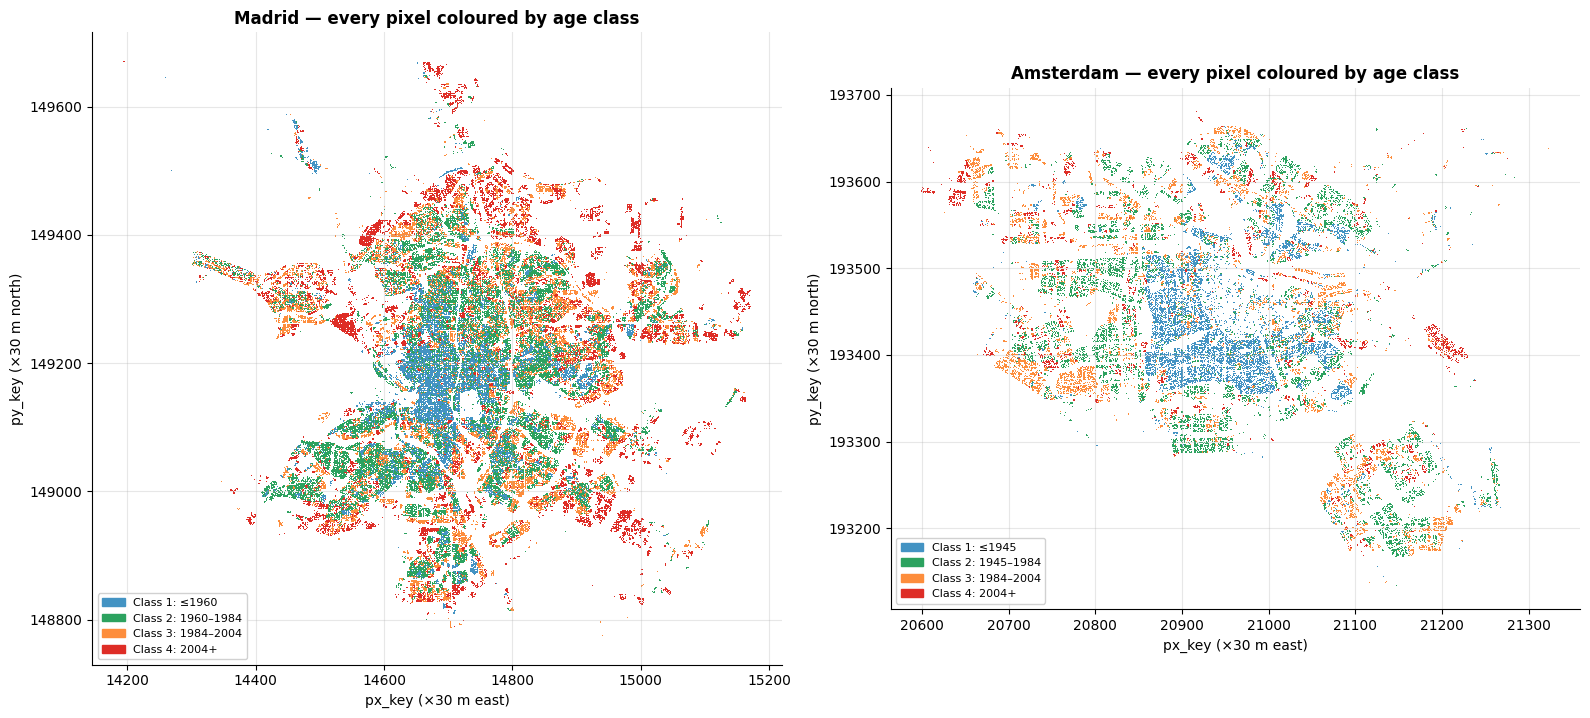

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
for ax, c in zip(axes, CITIES):
    p = pix[c]
    ax.scatter(p.px_key, p.py_key, c=p.age_class.map(CLASS_COLORS), s=0.6, marker='s', linewidths=0)
    ax.set_aspect('equal'); ax.set_title(f'{c} — every pixel coloured by age class', fontweight='bold')
    ax.set_xlabel('px_key (×30 m east)'); ax.set_ylabel('py_key (×30 m north)')
    lab = class_labels(c)
    ax.legend(handles=[mpatches.Patch(color=CLASS_COLORS[k], label=f'Class {k}: {lab[k]}') for k in [1,2,3,4]],
              loc='lower left', fontsize=8, framealpha=.9)
plt.tight_layout(); plt.show()

**What the maps show:**
- Pixels only exist where there are buildings (≥ 15 % coverage) — empty areas are parks, water, fields, roads.
- **Classes form neighbourhoods**: old centres (blue, class 1) in the middle, newer rings and developments (orange/red) towards the edges. Age is **spatially clustered**.
- ➡️ Two consequences: (1) a pixel's *neighbours* are a strong clue to its age (spatial context feature); (2) neighbouring pixels are not independent, which matters for fair testing (Part 13).

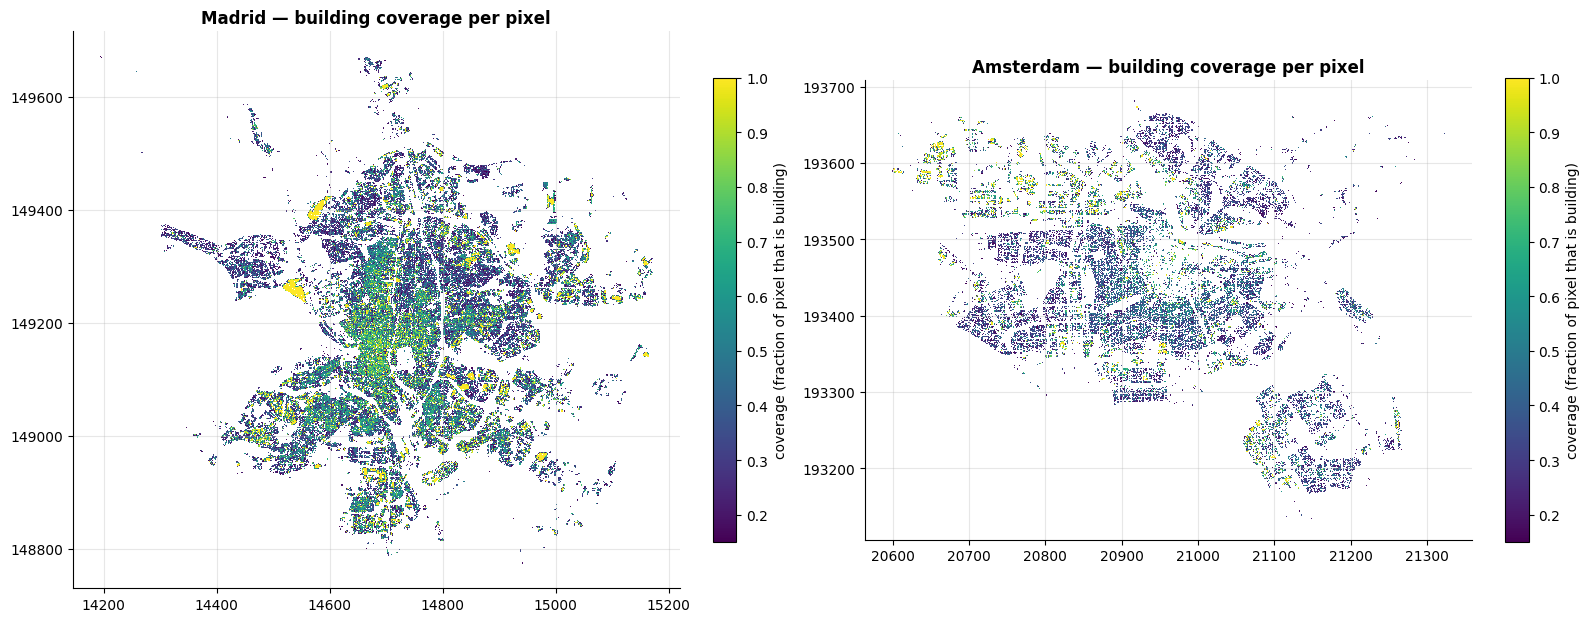

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
for ax, c in zip(axes, CITIES):
    p = pix[c]
    sc = ax.scatter(p.px_key, p.py_key, c=p.coverage, s=0.6, marker='s', cmap='viridis', vmin=.15, vmax=1, linewidths=0)
    ax.set_aspect('equal'); ax.set_title(f'{c} — building coverage per pixel', fontweight='bold')
    plt.colorbar(sc, ax=ax, fraction=.035, label='coverage (fraction of pixel that is building)')
plt.tight_layout(); plt.show()

**Coverage map:** bright (yellow) = almost fully built squares (dense historic cores); dark = mostly roads, gardens, water with some building. Most of each city is in between — **most pixels are mixtures**.

---
# Part 5 — The time dimension

**What we do:** check how many years each pixel has, and how many pixels are present each year.

**Why it matters:** our features will be built from each pixel's history. A pixel with only 10 years of data gives weaker, noisier features than one with 42.

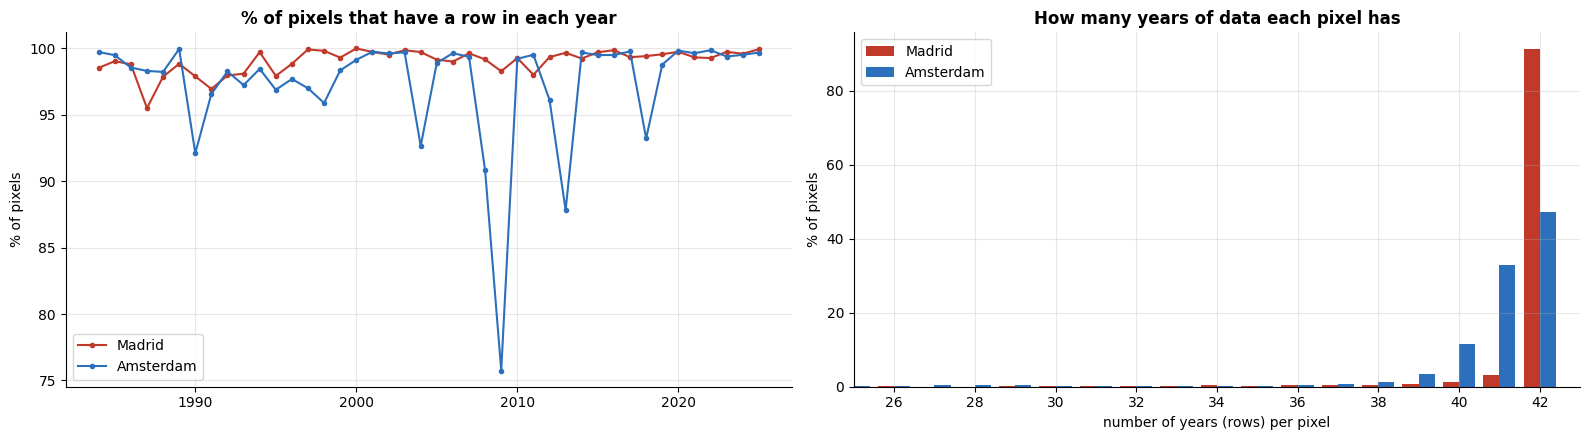

Madrid    : all 42 years: 91% of pixels | < 30 years: 440 pixels | minimum: 13 years
Amsterdam : all 42 years: 47% of pixels | < 30 years: 397 pixels | minimum: 8 years


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for c in CITIES:
    yc = raw[c].groupby('year').size() / len(pix[c]) * 100
    axes[0].plot(yc.index, yc.values, marker='o', ms=3, color=CITY_COLORS[c], label=c)
    vc = pix[c].n_years.value_counts().sort_index()
    axes[1].bar(vc.index + (-.2 if c == 'Madrid' else .2), vc.values / vc.sum() * 100, width=.4, color=CITY_COLORS[c], label=c)
axes[0].set_title('% of pixels that have a row in each year', fontweight='bold'); axes[0].set_ylabel('% of pixels'); axes[0].legend()
axes[1].set_title('How many years of data each pixel has', fontweight='bold'); axes[1].set_xlabel('number of years (rows) per pixel')
axes[1].set_ylabel('% of pixels'); axes[1].legend(); axes[1].set_xlim(25, 43)
plt.tight_layout(); plt.show()

for c in CITIES:
    n = pix[c].n_years
    print(f"{c:10s}: all 42 years: {(n==42).mean():.0%} of pixels | < 30 years: {(n<30).sum()} pixels | minimum: {n.min()} years")

**What we learned:**
- Almost every pixel has **37–42 years** of history — plenty for time-series features.
- Some years are thinner (e.g. Amsterdam 2009, 2013) — whole years where clouds hid many pixels.
- A row exists for a year if *any* of its 3 photos exists — but a row can still contain only cloudy photos. The real "usable" history is checked in Part 9.

---
# Part 6 — The 3 photos per year, and their quality flags

### 6.1 Turning wide into long

Working with `Blue_1, Blue_2, Blue_3` side by side is awkward. We reshape into **long format**: **one row per photo** (pixel, year, slot, 6 bands, QA, doy, scene, sensor). This table, `obs`, is the basis for all cleaning.

In [11]:
def to_long(df):
    parts = []
    for s in SLOTS:
        ren = {f'{b}_{s}': b for b in BANDS}
        ren.update({f'QA_PIXEL_{s}': 'QA_PIXEL', f'QA_RADSAT_{s}': 'QA_RADSAT', f'doy_{s}': 'doy',
                    f'scene_id_{s}': 'scene_id', f'dataset_{s}': 'dataset', f'qa_valid_{s}': 'qa_valid'})
        part = df[PID + ['year'] + list(ren)].rename(columns=ren)
        part['slot'] = np.int8(s)
        parts.append(part)
    o = pd.concat(parts, ignore_index=True)
    o[BANDS] = o[BANDS].astype('float32')
    o['scene_id'] = o['scene_id'].astype('category')
    o['dataset']  = o['dataset'].map(SENSOR_NAMES).astype('category')
    return o

obs = {c: to_long(df) for c, df in raw.items()}
for c in CITIES:
    print(f"{c:10s}: {len(obs[c]):,} photo-observations  (= rows × 3)")
obs['Madrid'].head()

Madrid    : 9,518,295 photo-observations  (= rows × 3)
Amsterdam : 3,188,631 photo-observations  (= rows × 3)


,px_key,py_key,year,Blue,Green,Red,NIR,SWIR1,SWIR2,QA_PIXEL,QA_RADSAT,doy,scene_id,dataset,qa_valid,slot
0,14194,149671,1984,9184.207031,9821.585938,10537.317383,15736.041016,16615.345703,13306.133789,5440,0,199,LT05_L2SP_201032_19840717_20200918_02_T1,TM (L5),True,1
1,14196,149670,1984,9513.961914,10631.701172,11703.544922,17431.326172,18064.712891,14072.572266,5440,0,199,LT05_L2SP_201032_19840717_20200918_02_T1,TM (L5),True,1
2,14259,149645,1984,10933.764648,12355.941406,14021.262695,18071.968750,18510.203125,16110.348633,5440,0,199,LT05_L2SP_201032_19840717_20200918_02_T1,TM (L5),True,1
3,14268,149501,1984,10224.352539,11437.046875,12968.022461,17290.304688,20047.041016,16108.329102,5440,0,199,LT05_L2SP_201032_19840717_20200918_02_T1,TM (L5),True,1
4,14302,149354,1984,11413.229492,12704.223633,14453.562500,18616.919922,19161.146484,16510.228516,5440,0,199,LT05_L2SP_201032_19840717_20200918_02_T1,TM (L5),True,1


Before we throw the raw wide table away, we also rebuild **the starter notebooks' method** (`make_flat_view`: take the *first* clean photo of each year, drop rows with Blue > 15 000). We keep it only to **compare** it with our cleaning in Part 9.

In [12]:
def notebook_flat_view(df, blue_max=15_000):
    out = df[PID + ['year']].copy()
    for b in BANDS:
        col = np.full(len(df), np.nan)
        for s in SLOTS:
            col = np.where(np.isnan(col) & df[f'qa_valid_{s}'].values, df[f'{b}_{s}'].values, col)
        out[b] = col
    out = out.dropna(subset=BANDS)
    return out[out.Blue <= blue_max].reset_index(drop=True)

nb_flat = {c: notebook_flat_view(df) for c, df in raw.items()}
for c in CITIES:
    print(f"{c:10s}: starter-notebook flat view keeps {len(nb_flat[c]):,} pixel-years")

del raw, mad, one_pixel           # free ~1.7 GB of memory – everything we need is now in obs / pix / nb_flat
import gc; gc.collect();

Madrid    : starter-notebook flat view keeps 3,137,920 pixel-years
Amsterdam : starter-notebook flat view keeps 1,049,960 pixel-years


### 6.2 Decoding `QA_PIXEL` — what the quality number really means

`QA_PIXEL` is a 16-bit number. Each **bit** (on/off switch) answers one question about that pixel in that photo (official Landsat Collection-2 definition):

| Bit(s) | Meaning when ON |
|---|---|
| 0 | **Fill** — no data |
| 1 | **Dilated cloud** — right next to a cloud |
| 2 | Cirrus (thin high cloud) — Landsat 8/9 only |
| 3 | **Cloud** |
| 4 | **Cloud shadow** |
| 5 | **Snow** |
| 6 | **Clear** — none of the above |
| 7 | **Water** |
| 8–9 | Cloud confidence (1 = low, 2 = medium, 3 = high) |
| 10–11 | Shadow confidence |
| 12–13 | Snow confidence |
| 14–15 | Cirrus confidence (L8/9) |

Example: **5440** in binary is `0001 0101 0100 0000` → bits 6, 8, 10, 12 on → *clear, low cloud / shadow / snow confidence* → a good observation.

**What we do:** decode every code into a readable category and check how the organisers' `qa_valid` flag relates to it.

In [13]:
def decode_qa(q):
    q = np.asarray(q).astype(np.int64)
    bit = lambda b: (q >> b) & 1
    cat = np.select(
        [bit(0) == 1, bit(3) == 1, bit(4) == 1, bit(1) == 1, bit(5) == 1, (bit(7) == 1) & (bit(6) == 0), bit(6) == 1],
        ['fill (no data)', 'cloud', 'cloud shadow', 'near cloud (dilated)', 'snow', 'water', 'clear'], 'other')
    cirrus_conf = (q >> 14) & 3
    return cat, cirrus_conf

for c in CITIES:
    obs[c]['qa_cat'], obs[c]['cirrus_conf'] = decode_qa(obs[c]['QA_PIXEL'])
    obs[c]['qa_cat'] = obs[c]['qa_cat'].astype('category')

o = obs['Madrid']
top = (o.groupby('QA_PIXEL').agg(n=('qa_valid', 'size'), qa_valid_rate=('qa_valid', 'mean'), category=('qa_cat', 'first'))
         .sort_values('n', ascending=False).head(14))
top['binary'] = [format(int(v), '016b') for v in top.index]
top['share_%'] = (top.n / len(o) * 100).round(2)
print("Most common QA_PIXEL codes in Madrid:")
top[['binary', 'category', 'n', 'share_%', 'qa_valid_rate']]

Most common QA_PIXEL codes in Madrid:


,binary,category,n,share_%,qa_valid_rate
QA_PIXEL,,,,,
5440,0001010101000000,clear,7070621,74.28,1.0
21824,0101010101000000,clear,1760601,18.50,1.0
1,0000000000000001,fill (no data),137957,1.45,0.0
7440,0001110100010000,cloud shadow,112637,1.18,0.0
5896,0001011100001000,cloud,80957,0.85,0.0
5442,0001010101000010,near cloud (dilated),76977,0.81,0.0
13600,0011010100100000,snow,73780,0.78,0.0
5696,0001011001000000,clear,51119,0.54,1.0
5504,0001010110000000,water,39432,0.41,0.0


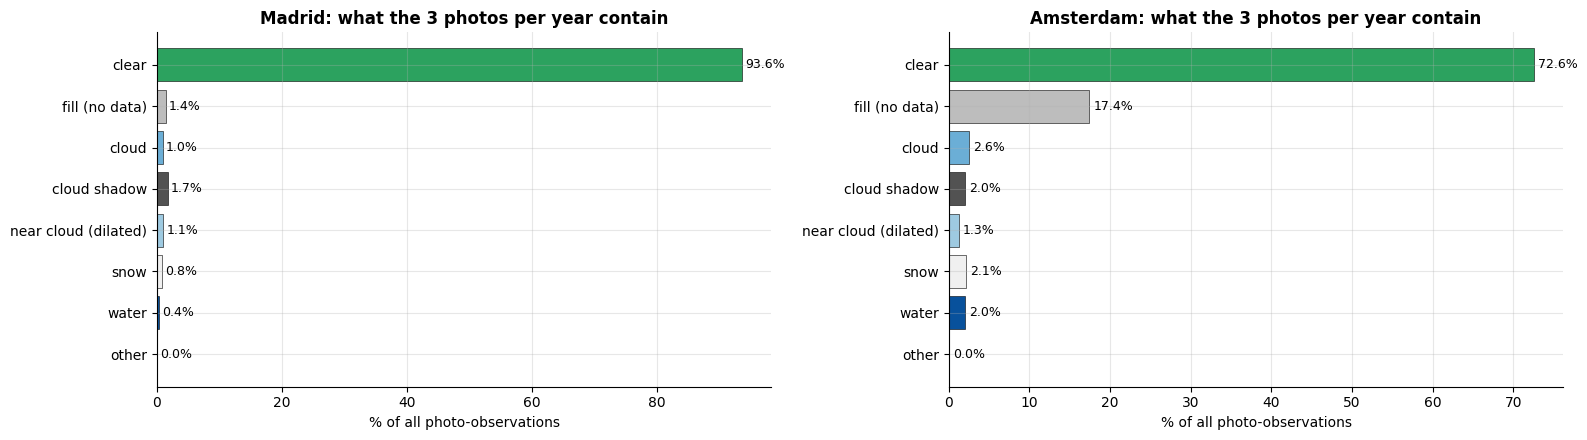


Madrid: QA category vs organisers' qa_valid flag
qa_valid               False    True 
qa_cat                               
clear                      0  8908409
cloud                  91003        0
cloud shadow          165417        0
fill (no data)        137957        0
near cloud (dilated)  100998        0
snow                   74045       92
water                  40374        0



Amsterdam: QA category vs organisers' qa_valid flag
qa_valid               False    True 
qa_cat                               
clear                      0  2315048
cloud                  81638        0
cloud shadow           63363        0
fill (no data)        555603        0
near cloud (dilated)   40519        0
snow                   67353      303
water                  64804        0


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
order = ['clear', 'fill (no data)', 'cloud', 'cloud shadow', 'near cloud (dilated)', 'snow', 'water', 'other']
cat_colors = ['#2ca25f', '#bdbdbd', '#6baed6', '#525252', '#9ecae1', '#f0f0f0', '#08519c', '#fdae6b']
for ax, c in zip(axes, CITIES):
    share = obs[c].qa_cat.value_counts(normalize=True).reindex(order).fillna(0) * 100
    bars = ax.barh(order[::-1], share.values[::-1], color=cat_colors[::-1], edgecolor='k', linewidth=.4)
    for b, v in zip(bars, share.values[::-1]):
        ax.text(v + .5, b.get_y() + b.get_height()/2, f'{v:.1f}%', va='center', fontsize=9)
    ax.set_title(f'{c}: what the 3 photos per year contain', fontweight='bold'); ax.set_xlabel('% of all photo-observations')
plt.tight_layout(); plt.show()

for c in CITIES:
    ct = pd.crosstab(obs[c].qa_cat, obs[c].qa_valid)
    print(f"\n{c}: QA category vs organisers' qa_valid flag")
    print(ct.to_string())

**What we learned:**
- `qa_valid = True` ⇔ the pixel is flagged **clear** (and not next to a cloud). Everything else — fill, cloud, shadow, dilated cloud, snow, water — is `qa_valid = False`. ✅ So `qa_valid` is a sound main filter.
- **Amsterdam is far cloudier**: about **73 %** of its photo-observations are clean vs **94 %** in Madrid. A big part of Amsterdam's loss is *fill* (no data — Landsat 7 stripes and scene edges).
- A handful of observations (92 in Madrid, 303 in Amsterdam) carry both the *snow* and the *clear* bit and are still `qa_valid = True` — negligible, but worth knowing.
- **Water** is excluded too — matters in Amsterdam (canals): pixels next to water lose observations.
- `qa_valid` does **not** check **cirrus** (thin high cloud) — that is how hazy scenes slip through (Part 8).

### 6.3 How many clean photos per year?

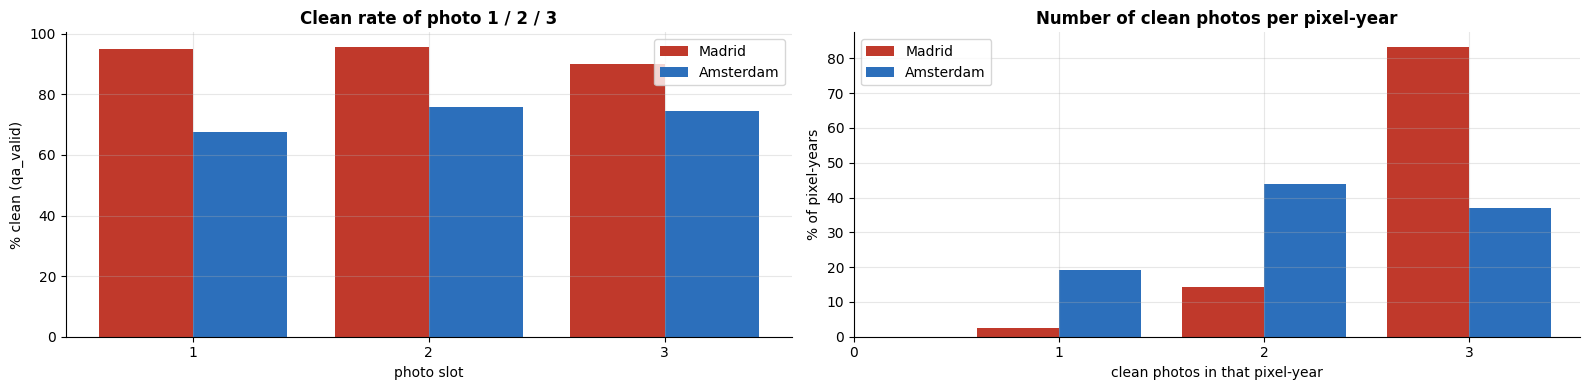

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for c in CITIES:
    rate = obs[c].groupby('slot').qa_valid.mean() * 100
    axes[0].bar(rate.index + (-.2 if c == 'Madrid' else .2), rate.values, width=.4, color=CITY_COLORS[c], label=c)
    nv = obs[c].groupby(PID + ['year']).qa_valid.sum().value_counts(normalize=True).sort_index() * 100
    axes[1].bar(nv.index + (-.2 if c == 'Madrid' else .2), nv.values, width=.4, color=CITY_COLORS[c], label=c)
axes[0].set_xticks(SLOTS); axes[0].set_xlabel('photo slot'); axes[0].set_ylabel('% clean (qa_valid)')
axes[0].set_title('Clean rate of photo 1 / 2 / 3', fontweight='bold'); axes[0].legend()
axes[1].set_xticks([0, 1, 2, 3]); axes[1].set_xlabel('clean photos in that pixel-year'); axes[1].set_ylabel('% of pixel-years')
axes[1].set_title('Number of clean photos per pixel-year', fontweight='bold'); axes[1].legend()
plt.tight_layout(); plt.show()

**What we learned:** Madrid usually has **3 clean photos** per year; Amsterdam often only 1–2. The starter notebook keeps just **one** of them — we will use all of them (Part 9).

---
# Part 7 — When and by which satellite were the photos taken?

### 7.1 Season (`doy`)

The starter Notebook 1 says scenes come from **summer (June–August)**. Let's check with the actual dates of the *clean* photos.

**Why it matters:** in winter the sun is low (long shadows, darker values), trees lose leaves (less NIR), snow may appear. If photos come from different seasons in different years, the year-to-year changes are partly **season noise**, not building change.

Madrid    : clean photos taken in June–August: 50%   (day-of-year range 15–364)


Amsterdam : clean photos taken in June–August: 31%   (day-of-year range 31–343)


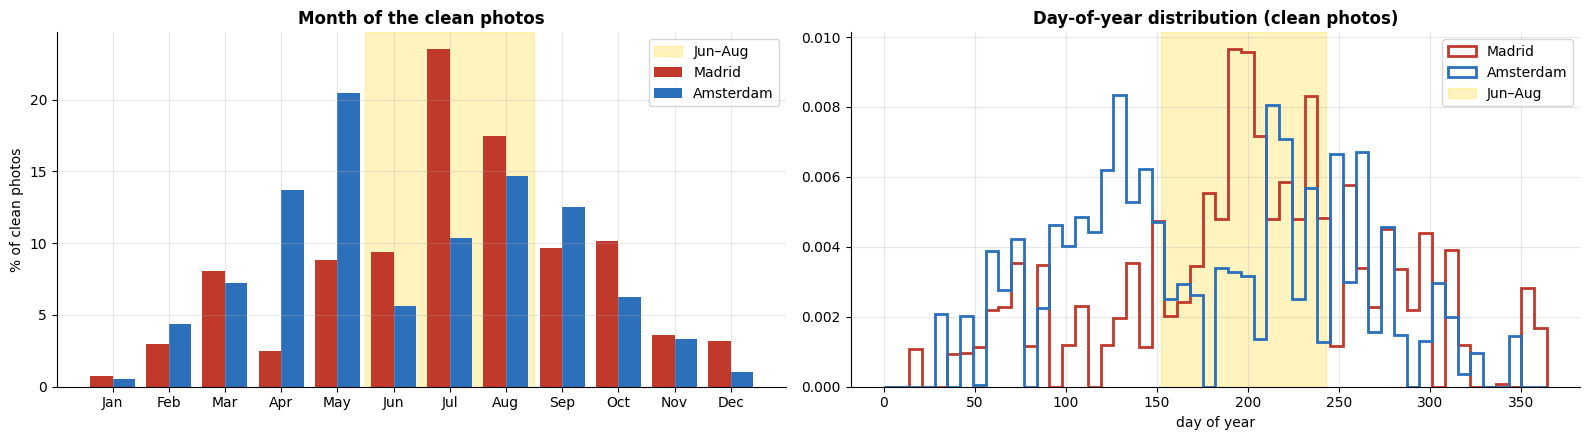

In [16]:
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
def doy_to_month(doy):
    return pd.to_datetime(doy.astype(int) - 1, unit='D', origin='2001-01-01').dt.month

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for c in CITIES:
    v = obs[c][obs[c].qa_valid]
    obs[c]['month'] = doy_to_month(obs[c].doy).astype('int8')
    m = obs[c].loc[obs[c].qa_valid, 'month'].value_counts(normalize=True).reindex(range(1, 13)).fillna(0) * 100
    axes[0].bar(np.arange(1, 13) + (-.2 if c == 'Madrid' else .2), m.values, width=.4, color=CITY_COLORS[c], label=c)
    axes[1].hist(v.doy, bins=np.arange(0, 370, 7), histtype='step', lw=2, color=CITY_COLORS[c], density=True, label=c)
    jja = obs[c].loc[obs[c].qa_valid, 'month'].isin([6, 7, 8]).mean()
    print(f"{c:10s}: clean photos taken in June–August: {jja:.0%}   (day-of-year range {v.doy.min()}–{v.doy.max()})")
for ax in axes: ax.axvspan(*( (5.5, 8.5) if ax is axes[0] else (152, 243) ), color='gold', alpha=.25, label='Jun–Aug', zorder=0)
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(MONTHS); axes[0].set_ylabel('% of clean photos')
axes[0].set_title('Month of the clean photos', fontweight='bold'); axes[0].legend()
axes[1].set_xlabel('day of year'); axes[1].set_title('Day-of-year distribution (clean photos)', fontweight='bold'); axes[1].legend()
plt.tight_layout(); plt.show()

**🔴 Surprise:** the photos are **not summer-only** — they are spread over the whole year. In Amsterdam most clean photos are *outside* June–August (spring and autumn dominate, because summer is often cloudy there).

Does season really change the values? Let's measure the typical (median) value per month:

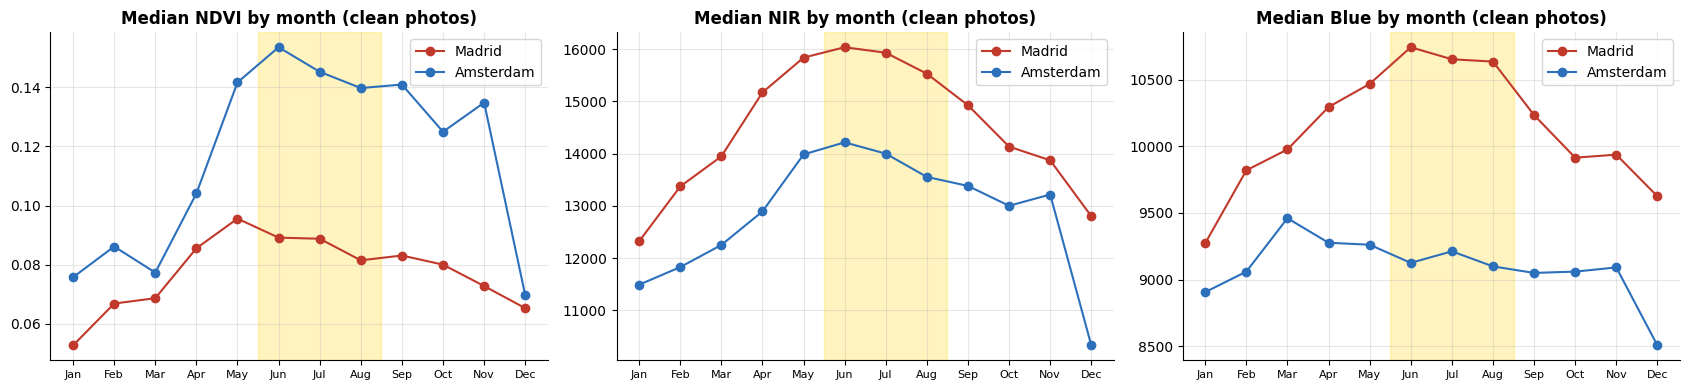

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for c in CITIES:
    v = obs[c][obs[c].qa_valid]
    ndvi = (v.NIR - v.Red) / (v.NIR + v.Red)
    g = pd.DataFrame({'month': v.month, 'NDVI': ndvi, 'NIR': v.NIR, 'Blue': v.Blue}).groupby('month').median()
    for ax, col in zip(axes, ['NDVI', 'NIR', 'Blue']):
        ax.plot(g.index, g[col], marker='o', color=CITY_COLORS[c], label=c)
for ax, col in zip(axes, ['NDVI', 'NIR', 'Blue']):
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(MONTHS, fontsize=8); ax.set_title(f'Median {col} by month (clean photos)', fontweight='bold')
    ax.axvspan(5.5, 8.5, color='gold', alpha=.25, zorder=0); ax.legend()
plt.tight_layout(); plt.show()

**What we learned:** values follow a clear **seasonal cycle** (vegetation green-up in spring/summer, darker low-sun winter scenes). Because each year's photos come from different months, **part of the year-to-year variation is just season**.

➡️ **Decision:** when building one value per year (Part 9) we **prefer photos from the warm season (May–September)** and only fall back to other months if a year has none. We also keep the photo month so it can be used as a control.

### 7.2 Which satellite?

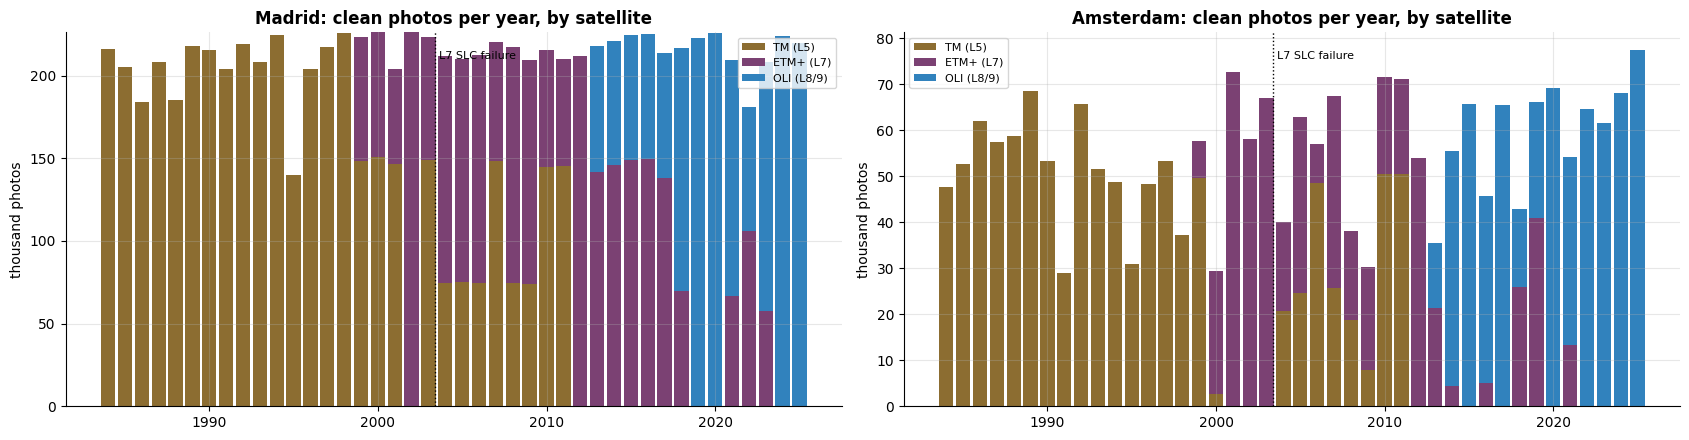

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for ax, c in zip(axes, CITIES):
    v = obs[c][obs[c].qa_valid]
    ct = pd.crosstab(v.year, v.dataset)
    ct = ct[[s for s in SENSOR_COLORS if s in ct.columns]]
    bottom = np.zeros(len(ct))
    for s in ct.columns:
        ax.bar(ct.index, ct[s] / 1e3, bottom=bottom, color=SENSOR_COLORS[s], label=s, width=.85); bottom += ct[s].values / 1e3
    ax.set_title(f'{c}: clean photos per year, by satellite', fontweight='bold'); ax.set_ylabel('thousand photos'); ax.legend(fontsize=8)
    ax.axvline(2003.4, color='k', ls=':', lw=1); ax.text(2003.6, ax.get_ylim()[1]*.93, 'L7 SLC failure', fontsize=8)
plt.tight_layout(); plt.show()

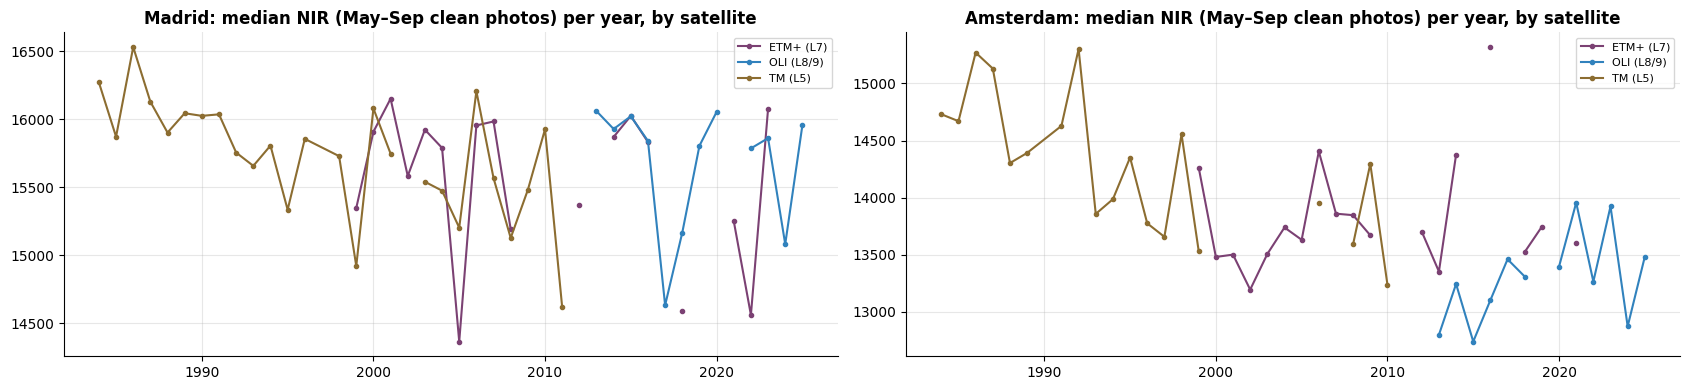

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(17, 4))
for ax, c in zip(axes, CITIES):
    v = obs[c][obs[c].qa_valid & obs[c].month.between(5, 9)]
    g = v.groupby(['year', 'dataset'], observed=True).NIR.median().unstack()
    for s in g.columns:
        ax.plot(g.index, g[s], marker='o', ms=3, color=SENSOR_COLORS[s], label=s)
    ax.set_title(f'{c}: median NIR (May–Sep clean photos) per year, by satellite', fontweight='bold'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What we learned:**
- In **Amsterdam**, Landsat 8/9 (OLI, blue line) years read clearly **darker in NIR** (≈ 500–1 000 lower) than the Landsat 5/7 years around them — a **sensor offset** that could look like "the city got darker".
- **1984–1998**: Landsat 5 (TM) only. **1999–2012**: a mix of Landsat 5 and 7. **2013+**: Landsat 8/9 (OLI), with some Landsat 7 still used (Madrid 2021–2023 relies heavily on L7, whose orbit had drifted late in its life).
- The organisers harmonised the sensors, and in overlapping years the lines are close — but small **sensor offsets remain**.
- ⚠️ Because the sensor changes with the *year*, a model could confuse "which satellite" with "what changed on the ground". Taking a **median over several photos** and working with **ratios** (indices) reduces this.

---
# Part 8 — The band values: outliers, broken scenes, saturation

**What we do:** look at the distribution of each band for **clean** photos, count impossible values (zeros, saturation), and look for whole photos (scenes) that are broken.

Normal urban reflectance (stored integers) sits roughly between **7 000 and 25 000**. Values above ~30 000 in the visible bands are almost always haze, snow or broken data.

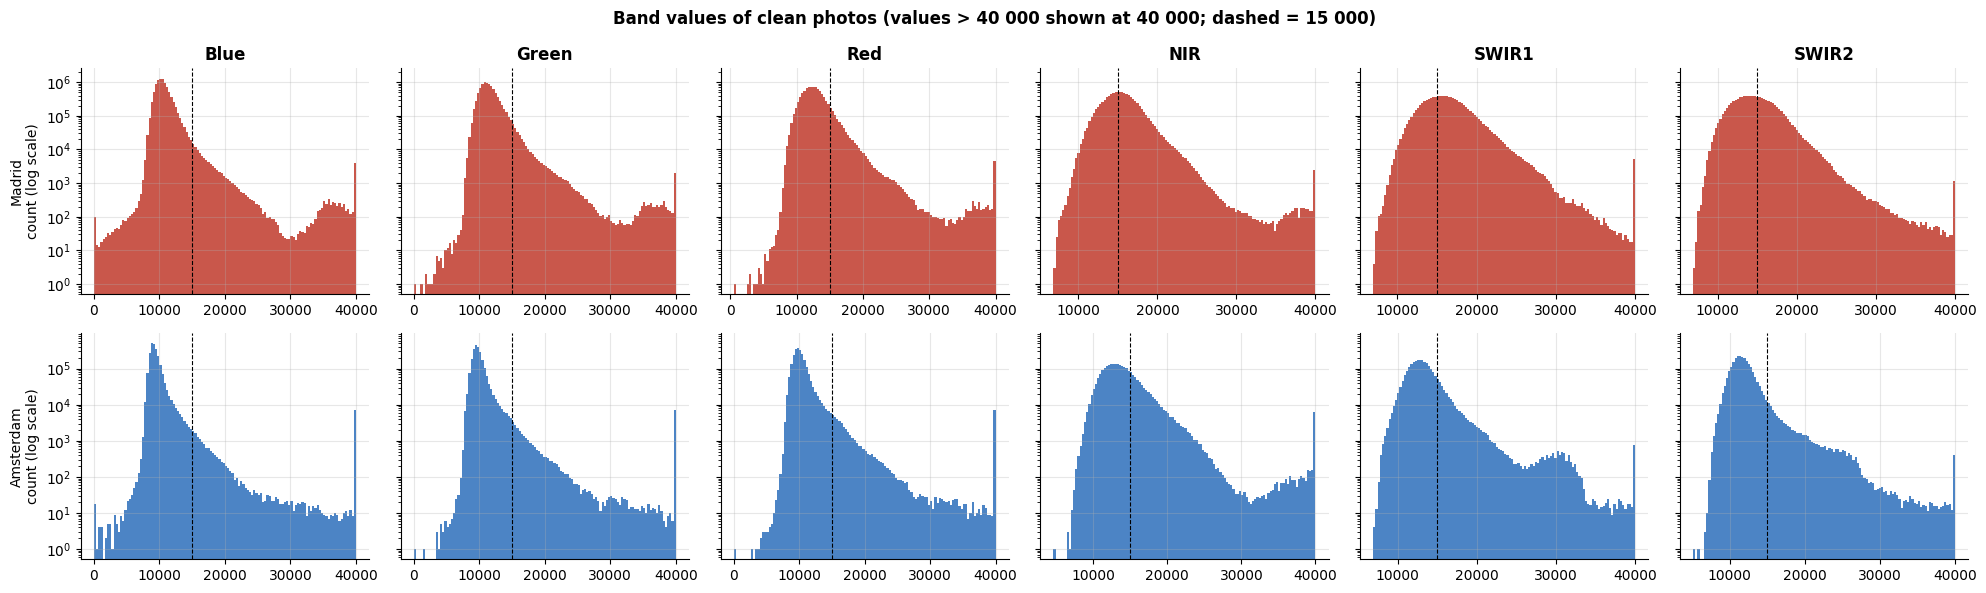

Madrid    : clean photos with a zero band: 78 | saturated (QA_RADSAT>0): 13,687 | Blue > 15 000: 102,180 | high-confidence cirrus: 1


Amsterdam : clean photos with a zero band: 18 | saturated (QA_RADSAT>0): 8,219 | Blue > 15 000: 20,580 | high-confidence cirrus: 6


In [20]:
fig, axes = plt.subplots(2, 6, figsize=(20, 6), sharey='row')
for r, c in enumerate(CITIES):
    v = obs[c][obs[c].qa_valid]
    for i, b in enumerate(BANDS):
        ax = axes[r, i]
        ax.hist(v[b].clip(0, 40000), bins=120, color=CITY_COLORS[c], alpha=.85)
        ax.set_yscale('log'); ax.axvline(15000, color='k', ls='--', lw=.8)
        if r == 0: ax.set_title(b, fontweight='bold')
        if i == 0: ax.set_ylabel(f'{c}\ncount (log scale)')
fig.suptitle('Band values of clean photos (values > 40 000 shown at 40 000; dashed = 15 000)', fontweight='bold')
plt.tight_layout(); plt.show()

for c in CITIES:
    v = obs[c][obs[c].qa_valid]
    print(f"{c:10s}: clean photos with a zero band: {(v[BANDS]==0).any(axis=1).sum():,} | "
          f"saturated (QA_RADSAT>0): {(v.QA_RADSAT>0).sum():,} | Blue > 15 000: {(v.Blue>15000).sum():,} | "
          f"high-confidence cirrus: {(v.cirrus_conf==3).sum():,}")

The log-scale histograms show a long tail of **very bright values**. Are they scattered pixels or whole bad photos? We compute, **per scene**, the median Blue and the share of pixels with Blue > 15 000.

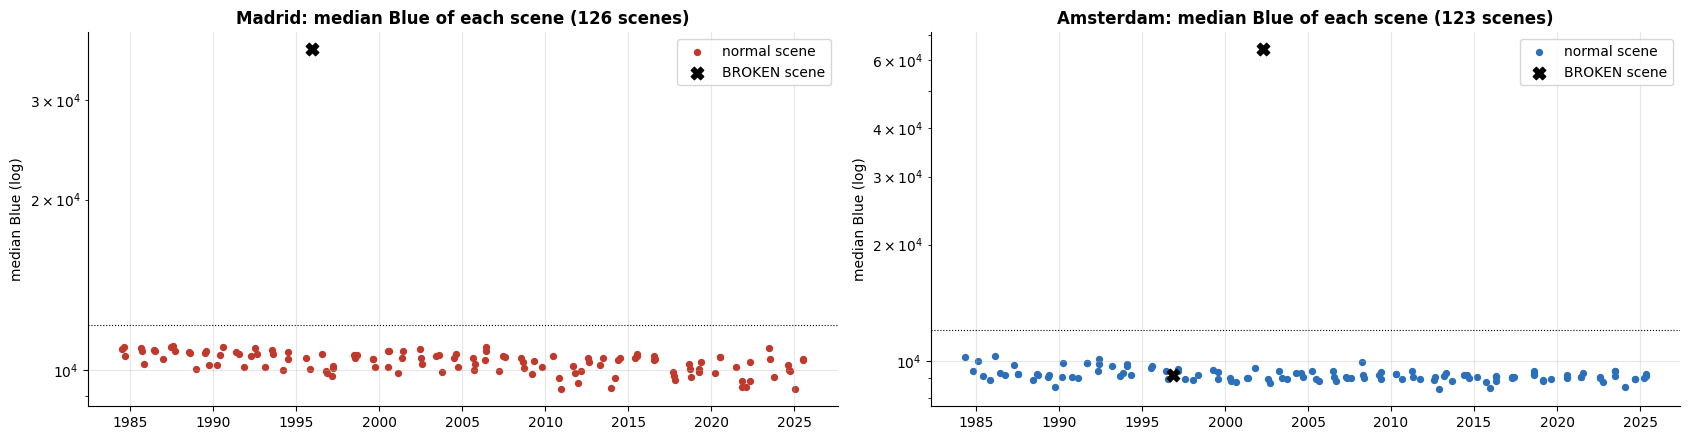

,city,date,sensor,n,median_blue,frac_blue_gt15k
scene_id,,,,,,
LT05_L2SP_201032_19951207_20211123_02_T2,Madrid,1995-12-07,TM (L5),4718,36816.066406,1.000000
LE07_L2SP_198023_20020417_20200916_02_T2,Amsterdam,2002-04-17,ETM+ (L7),6994,64126.003906,1.000000
LT05_L2SP_199023_19961109_20211124_02_T1,Amsterdam,1996-11-09,TM (L5),14432,9205.734375,0.120912


In [21]:
def scene_table(o):
    v = o[o.qa_valid]
    t = v.groupby('scene_id', observed=True).agg(n=('Blue', 'size'), median_blue=('Blue', 'median'),
                                                 frac_blue_gt15k=('Blue', lambda x: (x > 15000).mean()),
                                                 sensor=('dataset', 'first'))
    t['date'] = pd.to_datetime([str(s).split('_')[3] for s in t.index], format='%Y%m%d')
    return t.sort_values('date')

scenes = {c: scene_table(obs[c]) for c in CITIES}
BAD_RULE = lambda t: (t.median_blue > 12000) | (t.frac_blue_gt15k > 0.05)
BAD_SCENES = {c: set(scenes[c].index[BAD_RULE(scenes[c])]) for c in CITIES}

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for ax, c in zip(axes, CITIES):
    t = scenes[c]; bad = BAD_RULE(t)
    ax.scatter(t.date[~bad], t.median_blue[~bad], s=18, color=CITY_COLORS[c], label='normal scene')
    ax.scatter(t.date[bad], t.median_blue[bad], s=80, color='k', marker='X', label='BROKEN scene')
    ax.set_yscale('log'); ax.axhline(12000, color='k', ls=':', lw=.8)
    ax.set_title(f'{c}: median Blue of each scene ({len(t)} scenes)', fontweight='bold'); ax.set_ylabel('median Blue (log)'); ax.legend()
plt.tight_layout(); plt.show()

pd.concat([scenes[c].loc[sorted(BAD_SCENES[c])].assign(city=c) for c in CITIES])[['city', 'date', 'sensor', 'n', 'median_blue', 'frac_blue_gt15k']]

**🔴 Surprise:** our rule flags **3 broken scenes**: Madrid **7 Dec 1995** (every pixel Blue ≈ 36 800 — winter, very low sun), Amsterdam **17 Apr 2002** (every pixel Blue ≈ 64 000 — completely broken) and Amsterdam **9 Nov 1996** (12 % of pixels too bright). In other words, a few **whole scenes are broken** — every pixel in them is far too bright (haze, snow, low winter sun, or a processing fault). They passed the `qa_valid` filter anyway.

The starter notebook mentions one scene (29 May 2003) and only removes rows where Blue > 15 000 — that catches part of the problem but leaves the rest of each broken scene's values. ➡️ **Decision: drop broken scenes completely.**

Also:
- **Saturated** observations (`QA_RADSAT > 0`) have unknown true values → drop.
- **Zero** band values are impossible for a real surface → drop.
- **High-confidence cirrus** (Landsat 8/9) → drop.

---
# Part 9 — Cleaning: our rules and a better yearly value

## 9.1 Observation-level cleaning rules

Applied in order to every photo-observation. The table shows how many each rule removes.

| Rule | Removes | Why |
|---|---|---|
| R1 | `qa_valid == False` | cloud, shadow, snow, water, fill |
| R2 | photo from a **broken scene** | whole photo is wrong |
| R3 | `QA_RADSAT > 0` | saturated – true value unknown |
| R4 | any band == 0 | impossible value |
| R5 | high-confidence **cirrus** | thin cloud that `qa_valid` ignores |
| R6 | Blue > 15 000 | safety net for remaining haze |

In [22]:
def clean_obs(o, bad_scenes):
    rules = [
        ('R1 not qa_valid',          ~o.qa_valid),
        ('R2 broken scene',          o.scene_id.isin(bad_scenes)),
        ('R3 saturated (QA_RADSAT)', o.QA_RADSAT > 0),
        ('R4 zero band value',       (o[BANDS] == 0).any(axis=1)),
        ('R5 high-confidence cirrus', o.cirrus_conf == 3),
        ('R6 Blue > 15 000',         o.Blue > 15000),
    ]
    keep = np.ones(len(o), bool); log = []
    for name, bad in rules:
        removed = (keep & bad.values).sum(); keep &= ~bad.values
        log.append({'rule': name, 'removed': removed, 'remaining': keep.sum()})
    return o[keep].copy(), pd.DataFrame(log)

clean, clean_log = {}, {}
for c in CITIES:
    clean[c], clean_log[c] = clean_obs(obs[c], BAD_SCENES[c])
    clean_log[c]['removed_%_of_all'] = (clean_log[c].removed / len(obs[c]) * 100).round(2)
    print(f"\n{c}: {len(obs[c]):,} photo-observations → {len(clean[c]):,} clean ({len(clean[c])/len(obs[c]):.1%})")
    print(clean_log[c].to_string(index=False))


Madrid: 9,518,295 photo-observations → 8,800,748 clean (92.5%)
                     rule  removed  remaining  removed_%_of_all
          R1 not qa_valid   609794    8908501              6.41
          R2 broken scene     4718    8903783              0.05
 R3 saturated (QA_RADSAT)    13362    8890421              0.14
       R4 zero band value       78    8890343              0.00
R5 high-confidence cirrus        0    8890343              0.00
         R6 Blue > 15 000    89595    8800748              0.94



Amsterdam: 3,188,631 photo-observations → 2,281,625 clean (71.6%)
                     rule  removed  remaining  removed_%_of_all
          R1 not qa_valid   873280    2315351             27.39
          R2 broken scene    21426    2293925              0.67
 R3 saturated (QA_RADSAT)     1201    2292724              0.04
       R4 zero band value       18    2292706              0.00
R5 high-confidence cirrus        6    2292700              0.00
         R6 Blue > 15 000    11075    2281625              0.35


## 9.2 One value per pixel per year — a better "composite"

After cleaning, a pixel-year can still have 1, 2 or 3 clean photos. We need **one** value per band per year.

| Method | How | Problem |
|---|---|---|
| Starter notebook | take the **first** clean photo of the year | throws away the other photos; first photo is often early spring/winter |
| **Ours** | **median** of the clean photos, **preferring May–September** photos; fall back to all months only if none | uses all good data, less noise, more consistent season |

The **median** (middle value) is used instead of the mean because it ignores a single odd photo.

We also store `n_photos` (how many photos went into the value) and `season` (`warm` or `fallback`) for transparency.

In [23]:
def yearly_composite(cl):
    cl = cl.copy()
    cl['warm'] = cl.month.between(5, 9)
    keys = PID + ['year']
    all_med  = cl.groupby(keys)[BANDS].median()
    warm_med = cl[cl.warm].groupby(keys)[BANDS].median().reindex(all_med.index)
    use_warm = warm_med.notna().all(axis=1)
    comp = warm_med.where(use_warm, all_med)
    comp['n_photos'] = cl.groupby(keys).size()
    comp['season']   = np.where(use_warm, 'warm', 'fallback')
    comp['month']    = cl.groupby(keys).month.median()
    return comp.reset_index()

comp = {}
for c in CITIES:
    comp[c] = yearly_composite(clean[c])
    k = comp[c]
    print(f"{c:10s}: {len(k):,} pixel-years | from warm season: {(k.season=='warm').mean():.0%} | "
          f"photos per value: {k.n_photos.value_counts(normalize=True).sort_index().round(2).to_dict()}")

Madrid    : 3,147,969 pixel-years | from warm season: 97% | photos per value: {1: 0.03, 2: 0.15, 3: 0.82}


Amsterdam : 1,058,169 pixel-years | from warm season: 91% | photos per value: {1: 0.2, 2: 0.44, 3: 0.36}


## 9.3 Did it help? Measuring noise

A building's reflectance should change slowly from year to year (except at construction). So a good yearly series should have **small year-to-year jumps** for most pixels. We measure, per pixel, the **median absolute year-to-year change of NDVI** — lower = smoother = less noise — and compare the starter method with ours.

Madrid    : median year-to-year NDVI jump  → starter (first clean photo): 0.0211 | ours (cleaned warm-season median): 0.0113  → noise reduced by 46%


Amsterdam : median year-to-year NDVI jump  → starter (first clean photo): 0.0363 | ours (cleaned warm-season median): 0.0217  → noise reduced by 40%


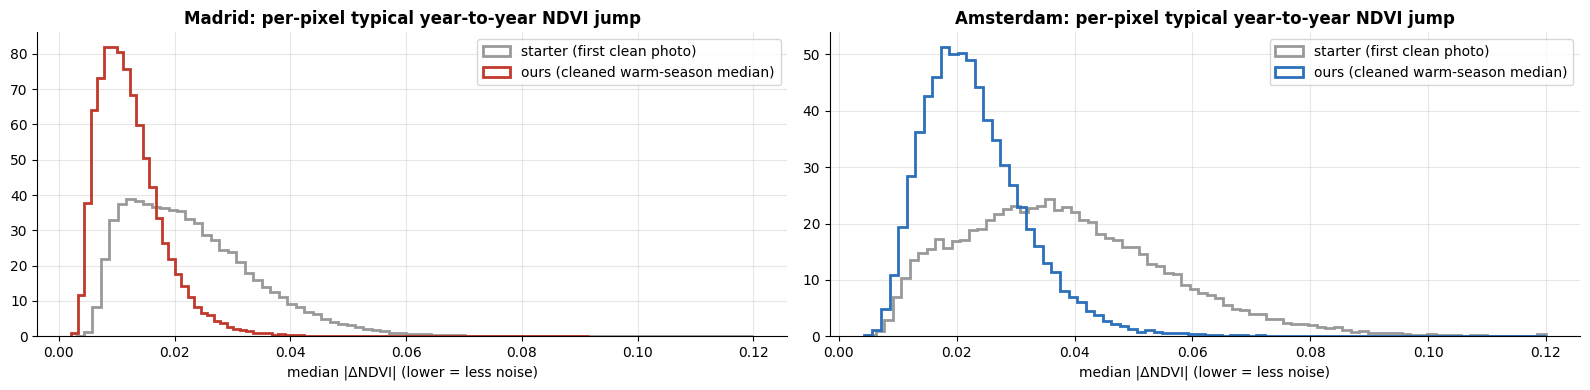

In [24]:
def ndvi(t): return (t.NIR - t.Red) / (t.NIR + t.Red)

def yoy_noise(t):
    t = t.sort_values(PID + ['year']).copy()
    t['ndvi'] = ndvi(t)
    t['d'] = t.groupby(PID).ndvi.diff().abs()
    return t.groupby(PID).d.median()

noise = {}
for c in CITIES:
    noise[c] = pd.DataFrame({'starter (first clean photo)': yoy_noise(nb_flat[c]),
                             'ours (cleaned warm-season median)': yoy_noise(comp[c])})
    print(f"{c:10s}: median year-to-year NDVI jump  → " +
          " | ".join(f"{k}: {v:.4f}" for k, v in noise[c].median().items()) +
          f"  → noise reduced by {1 - noise[c].median().iloc[1] / noise[c].median().iloc[0]:.0%}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, c in zip(axes, CITIES):
    for col, colr in zip(noise[c].columns, ['#999999', CITY_COLORS[c]]):
        ax.hist(noise[c][col].clip(0, .12), bins=80, histtype='step', lw=2, color=colr, label=col, density=True)
    ax.set_title(f'{c}: per-pixel typical year-to-year NDVI jump', fontweight='bold'); ax.set_xlabel('median |ΔNDVI| (lower = less noise)'); ax.legend()
plt.tight_layout(); plt.show()

### 9.4 Seeing it on one pixel

We pick a well-covered **Class 4** Madrid pixel (built after 2004) and plot: every clean photo (dots, coloured by month), the starter method (grey), and our composite (red). The dashed line is its construction year.

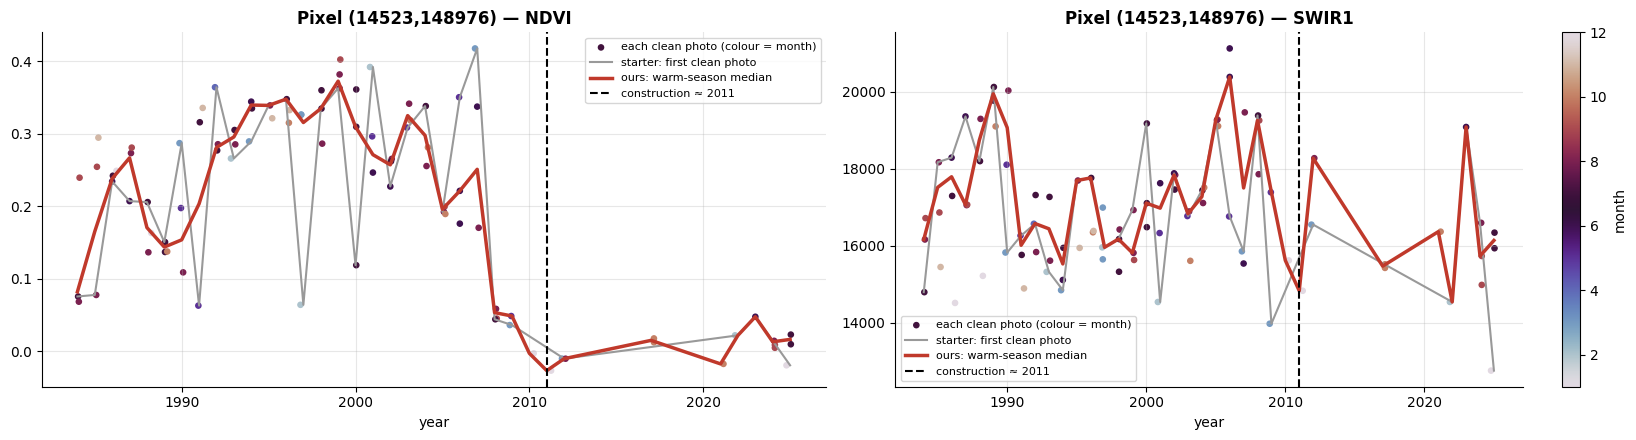

In [25]:
c = 'Madrid'
p4 = pix[c][(pix[c].age_class == 4) & (pix[c].coverage >= .7) & (pix[c].n_years == 42)]
k = comp[c].merge(p4[PID], on=PID)
k['ndvi'] = ndvi(k)
chg = k.groupby(PID).apply(lambda g: g.loc[g.year < 2000, 'ndvi'].median() - g.loc[g.year > 2012, 'ndvi'].median())
pxk, pyk = chg.idxmax()
wy = p4.set_index(PID).loc[(pxk, pyk), 'wmy']

def sel(t): return t[(t.px_key == pxk) & (t.py_key == pyk)].sort_values('year')
dots, starter, ours = sel(clean[c]), sel(nb_flat[c]), sel(comp[c])

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5))
for ax, (lab, fn) in zip(axes, [('NDVI', ndvi), ('SWIR1', lambda t: t.SWIR1)]):
    sc = ax.scatter(dots.year + (dots.month - 6) / 24, fn(dots), c=dots.month, cmap='twilight', s=14, label='each clean photo (colour = month)')
    ax.plot(starter.year, fn(starter), color='#999999', lw=1.5, label='starter: first clean photo')
    ax.plot(ours.year, fn(ours), color=CITY_COLORS[c], lw=2.5, label='ours: warm-season median')
    ax.axvline(wy, color='k', ls='--', label=f'construction ≈ {wy:.0f}')
    ax.set_title(f'Pixel ({pxk},{pyk}) — {lab}', fontweight='bold'); ax.set_xlabel('year'); ax.legend(fontsize=8)
plt.colorbar(sc, ax=axes[1], label='month'); plt.tight_layout(); plt.show()

**What we see:** this pixel's NDVI drops from ≈ 0.3 (vegetation) to ≈ 0 around **2008**, a few years *before* the recorded construction year (2011) — the site was cleared and built before the building was registered as finished. Missing stretches in the lines are years with no clean photo.

The individual photos (dots) scatter a lot within a year because of season. The starter line jumps around; our composite is smoother, so the **real event — construction — stands out** (vegetation drops / material changes around the dashed line). This construction "jump" is exactly the kind of signal our features should capture.

## 9.5 Gaps after cleaning

Some pixel-years have no clean photo left. How many years does each pixel keep?

In [26]:
for c in CITIES:
    yrs = comp[c].groupby(PID).size()
    print(f"{c:10s}: years with a clean value per pixel — median {yrs.median():.0f}, "
          f"min {yrs.min()}, pixels with < 30 years: {(yrs < 30).sum()} ({(yrs < 30).mean():.1%}), "
          f"pixels lost completely: {len(pix[c]) - len(yrs)}")

Madrid    : years with a clean value per pixel — median 42, min 6, pixels with < 30 years: 1206 (1.6%), pixels lost completely: 0
Amsterdam : years with a clean value per pixel — median 41, min 8, pixels with < 30 years: 579 (2.2%), pixels lost completely: 0


Gaps are small. In the feature step (Notebook 3) the remaining missing years can be filled by **linear interpolation** between neighbouring years — or features can be computed directly on the available years.

---
# Part 10 — The labels: from `weighted_mean_year` to age class

### 10.1 What the label really is

A pixel often contains several buildings. The organisers computed:

$$\text{weighted\_mean\_year} = \frac{\sum_i \text{year}_i \times \text{area}_i}{\sum_i \text{area}_i}$$

e.g. buildings from 1920 (300 m²), 1970 (100 m²) and 2010 (50 m²) → (1920·300 + 1970·100 + 2010·50) / 450 = **1941.1** → class 1 in both cities.

So the label is an **average** — a pixel labelled 1941 may still contain a new building.

### 10.2 Distribution of construction years

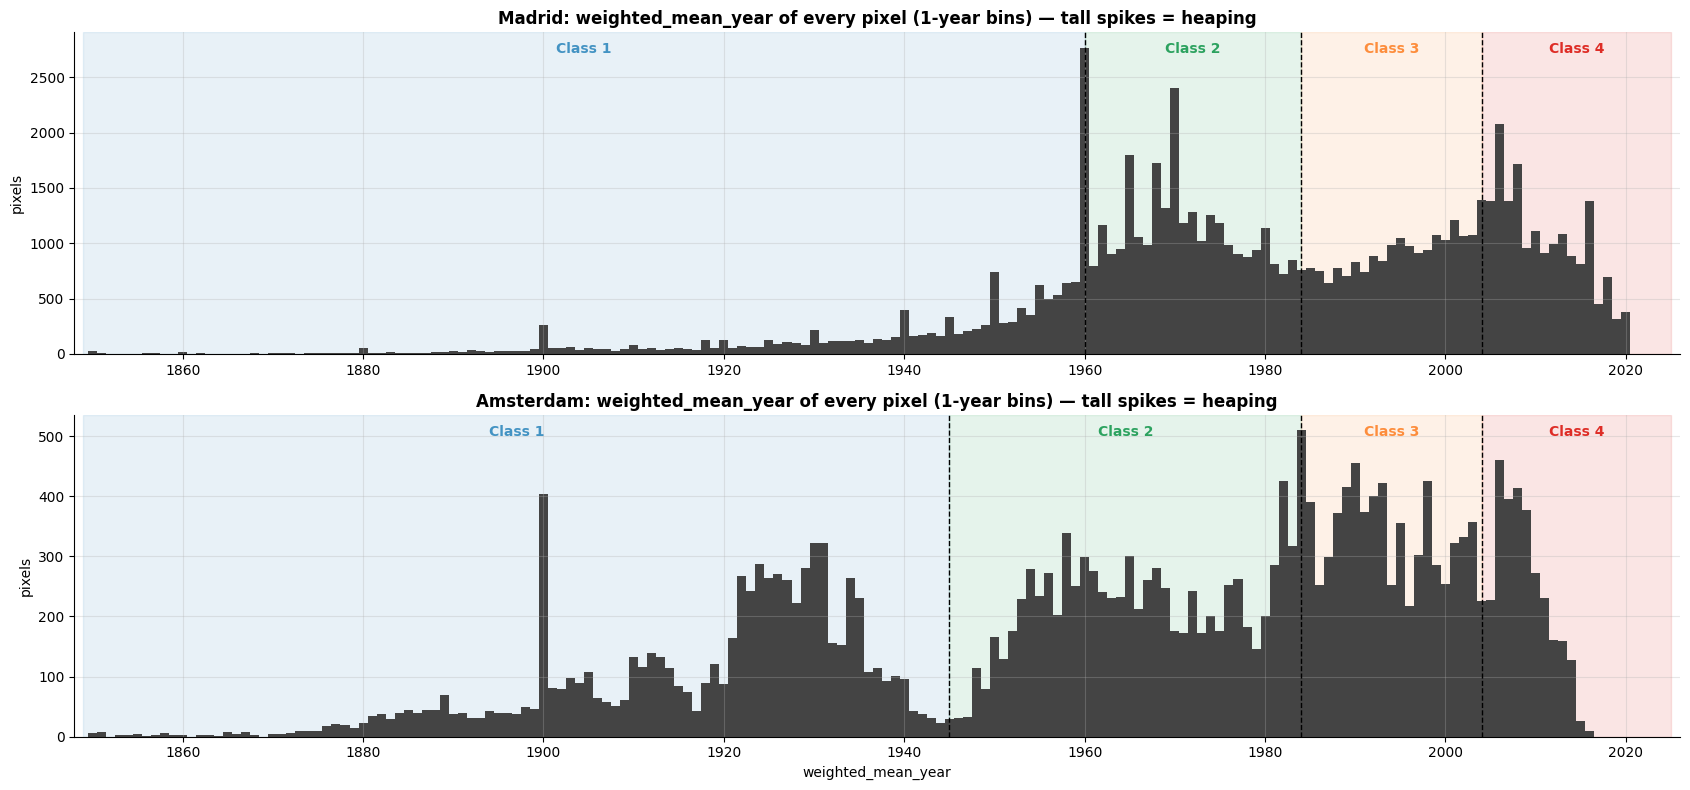

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(17, 8))
for ax, c in zip(axes, CITIES):
    p = pix[c]; ev = CLASS_EVENTS[c]
    edges = [1849, ev, 1984, 2004, 2025]
    for k in [1, 2, 3, 4]:
        ax.axvspan(edges[k-1], edges[k], color=CLASS_COLORS[k], alpha=.12)
        ax.text((edges[k-1] + edges[k]) / 2, 0.97, f'Class {k}', transform=ax.get_xaxis_transform(), ha='center', va='top',
                fontweight='bold', color=CLASS_COLORS[k])
    ax.hist(p.wmy, bins=np.arange(1849.5, 2025.5, 1), color='#444444')
    for e in [ev, 1984, 2004]: ax.axvline(e, color='k', ls='--', lw=1)
    ax.set_title(f'{c}: weighted_mean_year of every pixel (1-year bins) — tall spikes = heaping', fontweight='bold')
    ax.set_ylabel('pixels'); ax.set_xlim(1848, 2026)
axes[1].set_xlabel('weighted_mean_year')
plt.tight_layout(); plt.show()

### 10.3 Heaping — suspicious piles on single years

The spikes above are **heaping**: many pixels share one exact year. Round or default years (1900, 1960, 1970 …) usually mean the registry only had an approximate date.

In [28]:
for c in CITIES:
    p = pix[c]
    exact = p.wmy[p.wmy == p.wmy.round()]
    top = exact.value_counts().head(10)
    print(f"\n{c}: top-10 exact years (pixels)  → share of all pixels with an exact whole year: {len(exact)/len(p):.0%}")
    print('   ' + ', '.join(f"{int(y)}: {n}" for y, n in top.items()))
    ev = CLASS_EVENTS[c]
    print(f"   ⚠ pixels exactly ON the class-1/2 boundary year {ev}: {(p.wmy == ev).sum():,} "
          f"(= {(p.wmy == ev).sum() / (p.age_class == 1).sum():.0%} of class 1)")


Madrid: top-10 exact years (pixels)  → share of all pixels with an exact whole year: 61%
   1960: 2227, 2006: 1811, 1970: 1647, 2008: 1529, 2016: 1332, 2007: 1167, 2005: 1139, 1965: 1126, 2004: 1107, 1968: 1009
   ⚠ pixels exactly ON the class-1/2 boundary year 1960: 2,227 (= 16% of class 1)

Amsterdam: top-10 exact years (pixels)  → share of all pixels with an exact whole year: 73%
   1984: 429, 2006: 395, 1993: 365, 1900: 362, 1982: 359, 2008: 358, 1998: 346, 1989: 343, 2007: 341, 1990: 337
   ⚠ pixels exactly ON the class-1/2 boundary year 1945: 2 (= 0% of class 1)


**🔴 Finding:** Madrid has a large pile of pixels at **exactly 1960** — which is *exactly* its class 1/2 boundary. `pd.cut` puts them in **class 1**. If 1960 is a "default/unknown" date in the Madrid registry, these labels are unreliable and the class 1 vs 2 split gets blurred. ➡️ **Test training with and without them.**

### 10.4 Pixels near a class boundary (hard cases)

In [29]:
rows = []
for c in CITIES:
    p = pix[c]
    for b in [CLASS_EVENTS[c], 1984, 2004]:
        rows.append({'city': c, 'boundary': b, 'exactly on it': (p.wmy == b).sum(),
                     'within ±2 years': ((p.wmy - b).abs() <= 2).sum(),
                     '% of all pixels (±2y)': round(((p.wmy - b).abs() <= 2).mean() * 100, 1)})
pd.DataFrame(rows)

,city,boundary,exactly on it,within ±2 years,% of all pixels (±2y)
0,Madrid,1960,2227,5523,7.2
1,Madrid,1984,407,3554,4.7
2,Madrid,2004,1107,6693,8.8
3,Amsterdam,1945,2,124,0.5
4,Amsterdam,1984,429,1832,7.0
5,Amsterdam,2004,188,1550,6.0


These pixels sit **right at the edge** between two classes: a few years of label error flips their class. No model will get them all right — expect confusion between *neighbouring* classes (1↔2, 2↔3, 3↔4) more than between distant ones.

### 10.5 Label quality differs by class

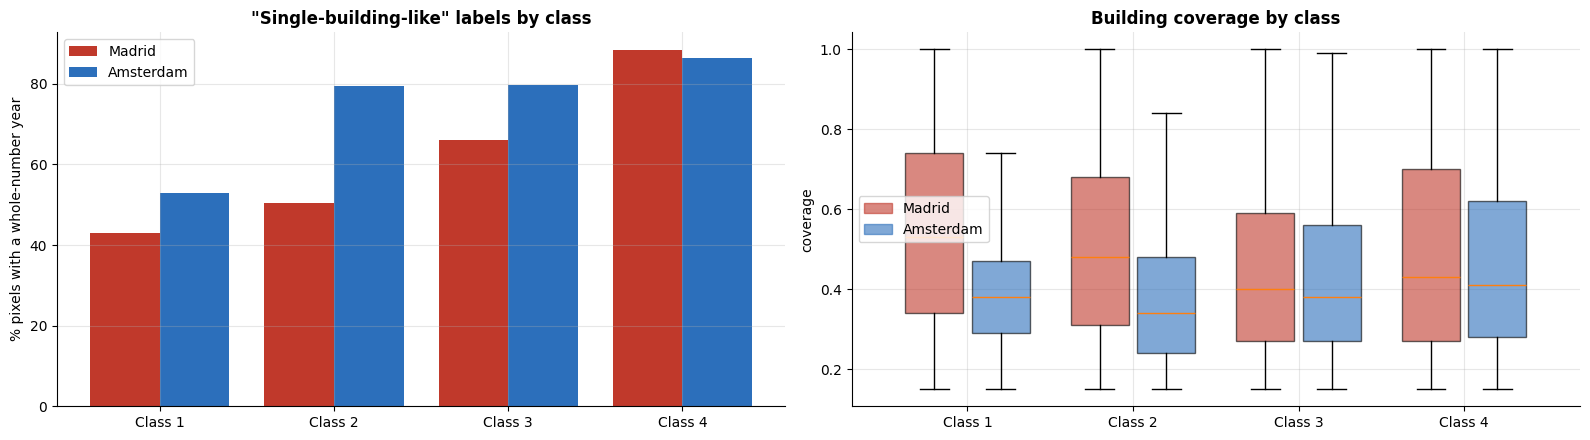

Madrid    : newest building year in data = 2021, oldest = 1850
Amsterdam : newest building year in data = 2016, oldest = 1850


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for i, c in enumerate(CITIES):
    p = pix[c]
    single = p.groupby('age_class').wmy.apply(lambda x: (x == x.round()).mean() * 100)
    axes[0].bar(np.arange(1, 5) + (-.2 if i == 0 else .2), single.values, width=.4, color=CITY_COLORS[c], label=c)
    data = [p.loc[p.age_class == k, 'coverage'] for k in [1, 2, 3, 4]]
    bp = axes[1].boxplot(data, positions=np.arange(1, 5) + (-.2 if i == 0 else .2), widths=.35, patch_artist=True, showfliers=False)
    for b in bp['boxes']: b.set_facecolor(CITY_COLORS[c]); b.set_alpha(.6)
axes[0].set_xticks([1, 2, 3, 4]); axes[0].set_xticklabels([f'Class {k}' for k in [1, 2, 3, 4]])
axes[0].set_ylabel('% pixels with a whole-number year'); axes[0].set_title('"Single-building-like" labels by class', fontweight='bold'); axes[0].legend()
axes[1].set_xticks([1, 2, 3, 4]); axes[1].set_xticklabels([f'Class {k}' for k in [1, 2, 3, 4]])
axes[1].set_ylabel('coverage'); axes[1].set_title('Building coverage by class', fontweight='bold')
axes[1].legend(handles=[mpatches.Patch(color=CITY_COLORS[c], alpha=.6, label=c) for c in CITIES])
plt.tight_layout(); plt.show()

for c in CITIES:
    print(f"{c:10s}: newest building year in data = {pix[c].wmy.max():.0f}, oldest = {pix[c].wmy.min():.0f}")

**What we learned:**
- A whole-number `weighted_mean_year` usually means **one building (or one development) fills the pixel** → a clean label. **Class 4 pixels are mostly clean**; **class 1 pixels are mostly mixtures** of several buildings of different ages → noisier labels.
- Coverage differs only slightly between classes, but **Amsterdam pixels are less built-up** than Madrid's.
- Amsterdam's newest building is from **2016**; Madrid's from **2021** → Amsterdam's class 4 covers a shorter period.

---
# Part 11 — Class imbalance

**Class imbalance** = some classes have many more examples than others. A model trained on imbalanced data tends to **over-predict the big class**, which hurts **macro F1** (every class counts equally).

We count **pixels, not rows** — each pixel has ~42 rows, so row counts exaggerate everything by 42×.

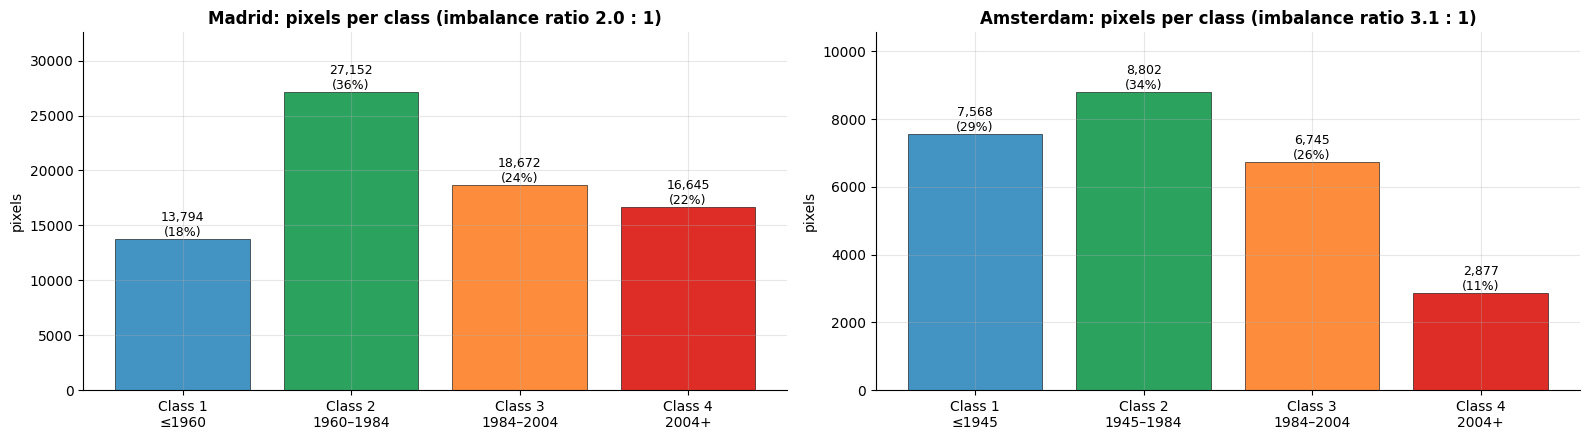

,Madrid,Amsterdam,"difference (Ams − Mad, %-points)"
age_class,,,
1,18.1,29.1,11.0
2,35.6,33.9,-1.7
3,24.5,26.0,1.5
4,21.8,11.1,-10.7


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
tab = []
for ax, c in zip(axes, CITIES):
    vc = pix[c].age_class.value_counts().sort_index()
    bars = ax.bar([f'Class {k}\n{class_labels(c)[k]}' for k in vc.index], vc.values, color=[CLASS_COLORS[k] for k in vc.index], edgecolor='k', lw=.4)
    for b, v in zip(bars, vc.values):
        ax.text(b.get_x() + b.get_width()/2, v, f'{v:,}\n({v/vc.sum():.0%})', ha='center', va='bottom', fontsize=9)
    ax.set_title(f'{c}: pixels per class (imbalance ratio {vc.max()/vc.min():.1f} : 1)', fontweight='bold'); ax.set_ylabel('pixels')
    ax.set_ylim(0, vc.max() * 1.2)
    tab.append(vc.rename(c))
plt.tight_layout(); plt.show()

share = pd.concat(tab, axis=1); share_pct = (share / share.sum() * 100).round(1)
share_pct['difference (Ams − Mad, %-points)'] = (share_pct.Amsterdam - share_pct.Madrid).round(1)
share_pct

In [32]:
from sklearn.utils.class_weight import compute_class_weight
for c in CITIES:
    y = pix[c].age_class.values
    w = compute_class_weight('balanced', classes=np.array([1, 2, 3, 4]), y=y)
    print(f"{c:10s}: 'balanced' class weights → " + ', '.join(f"class {k}: {v:.2f}" for k, v in zip([1, 2, 3, 4], w)))

Madrid    : 'balanced' class weights → class 1: 1.38, class 2: 0.70, class 3: 1.02, class 4: 1.15
Amsterdam : 'balanced' class weights → class 1: 0.86, class 2: 0.74, class 3: 0.96, class 4: 2.26


**Our take on imbalance:**

1. **Madrid: moderate (≈ 2 : 1).** Class 2 is the biggest. Without correction the model leans towards class 2 (the starter Notebook 4 confusion matrix shows exactly this).
2. **Amsterdam: stronger (≈ 3 : 1)**, mainly because **class 4 is small**.
3. **The bigger issue is *prior shift*** — the two cities have **different class mixes** (more class 1, much less class 4 in Amsterdam). A model carries Madrid's proportions with it → in Amsterdam it will **over-predict class 4 and under-predict class 1**.
4. **Few-shot training is balanced, the test is not**: we pick *n* pixels **per class**, but the Amsterdam test pixels follow Amsterdam's real mix.
5. **Hidden imbalances**: label quality (class 1 noisy vs class 4 clean), the 1960 heap, Amsterdam class 4 only to 2016.

**What we will do about it:**

| Fix | Where | How |
|---|---|---|
| Class weights | Madrid training | `class_weight='balanced'` (weights above) or balanced sampling |
| Prior / threshold adjustment | Amsterdam | rescale predicted probabilities to Amsterdam's class mix (estimated from the few labels or from unlabelled data) |
| Optimise for macro F1 | everywhere | choose thresholds/hyper-parameters by **macro F1**, never accuracy |
| Report per-class recall | everywhere | the confusion matrix shows whether a class is being ignored |
| ❌ Avoid naive oversampling (SMOTE) of time series | — | adds little with 3 000 – 27 000 pixels per class and can create unrealistic series |

---
# Part 12 — Madrid vs Amsterdam (domain shift)

**Domain shift** = the input data looks different in the new city. Here we compare the **typical value per pixel** (median of its yearly composites) for each band and NDVI.

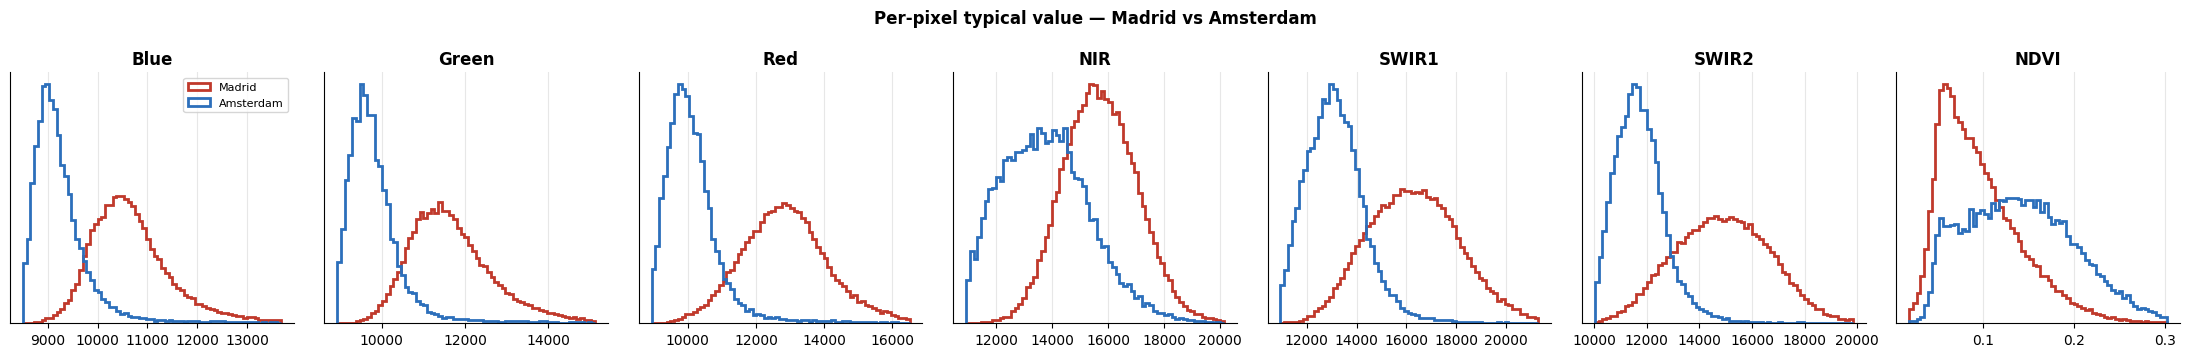

,Blue,Green,Red,NIR,SWIR1,SWIR2,NDVI
Madrid,10566.338,11537.617,12820.648,15678.373,16260.000,14865.265,0.088
Amsterdam,9121.094,9679.131,9983.188,13669.565,13041.383,11634.021,0.139


In [33]:
pixmed = {}
for c in CITIES:
    t = comp[c].copy(); t['NDVI'] = ndvi(t)
    pixmed[c] = t.groupby(PID)[BANDS + ['NDVI']].median()

fig, axes = plt.subplots(1, 7, figsize=(22, 3.6))
for ax, col in zip(axes, BANDS + ['NDVI']):
    lo, hi = np.percentile(np.r_[pixmed['Madrid'][col], pixmed['Amsterdam'][col]], [0.5, 99.5])
    for c in CITIES:
        ax.hist(pixmed[c][col], bins=np.linspace(lo, hi, 70), histtype='step', lw=2, density=True, color=CITY_COLORS[c], label=c)
    ax.set_title(col, fontweight='bold'); ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle('Per-pixel typical value — Madrid vs Amsterdam', fontweight='bold'); plt.tight_layout(); plt.show()

pd.DataFrame({c: pixmed[c].median() for c in CITIES}).round(3).T

**What we learned:**
- **Amsterdam is darker in every band** and greener (higher NDVI) — maritime climate, brick, water and trees vs Madrid's bright, dry concrete and stucco.
- A model that learns "bright = new" in Madrid will be **fooled in Amsterdam** — this is why the zero-shot result in starter Notebook 4 is poor.
- ➡️ Prefer features that **do not depend on absolute brightness**: band ratios / indices, **changes over time** (construction jumps), and values **standardised within each city**.

---
# Part 13 — Measuring performance correctly

### 13.1 The metric: macro F1

For each class: **precision** (when we say class k, how often right?), **recall** (of all real class k, how many found?), **F1** = 2·P·R / (P + R). **Macro F1** = plain average of the 4 F1s → a model that ignores a small class is punished. Always also look at the **confusion matrix**.

### 13.2 Two traps that inflate scores

1. **Row leakage:** each pixel has ~42 rows. If rows of the same pixel are in both training and test folds, the model is tested on what it already saw. ➡️ **One row per pixel** (aggregate the time series into features) or **group folds by pixel**.
2. **Spatial leakage (spatial autocorrelation):** neighbouring pixels share buildings and have similar ages. A random split puts a pixel in the test set and its neighbour in training → over-optimistic score. The hidden test sets may be spatially separate.

Let's **measure** how strong the neighbour effect is.

In [34]:
offsets = [(dx, dy) for dx in (-1, 0, 1) for dy in (-1, 0, 1) if (dx, dy) != (0, 0)]
for c in CITIES:
    p = pix[c][PID + ['age_class']]
    same = tot = 0
    for dx, dy in offsets:
        nb = p.rename(columns={'age_class': 'nb_class'}).assign(px_key=lambda d: d.px_key - dx, py_key=lambda d: d.py_key - dy)
        m = p.merge(nb, on=PID)
        same += (m.age_class == m.nb_class).sum(); tot += len(m)
    chance = (p.age_class.value_counts(normalize=True) ** 2).sum()
    print(f"{c:10s}: a neighbouring pixel has the SAME class {same/tot:.0%} of the time (random chance would be {chance:.0%})")

Madrid    : a neighbouring pixel has the SAME class 76% of the time (random chance would be 27%)
Amsterdam : a neighbouring pixel has the SAME class 87% of the time (random chance would be 28%)


Neighbours share their class far more often than chance → **spatial autocorrelation is strong**. That is great for *features* (neighbourhood context), but dangerous for *testing*.

### 13.3 Demonstration: random vs spatial cross-validation

We build a quick, simple feature set (per pixel: median, standard deviation, early-period and late-period median of each band and NDVI from our clean composite) and a fast model (`HistGradientBoostingClassifier`, class-weight balanced). Then we compare:
- **Random stratified 5-fold CV** — pixels shuffled at random.
- **Spatial block 5-fold CV** — the city is cut into **2 km × 2 km blocks**; whole blocks go to the test fold, so test pixels have no close neighbours in training.

*This is not our final model — just a check of how much the testing method changes the number.*

In [35]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix

def quick_features(cp):
    t = cp.copy(); t['NDVI'] = ndvi(t); cols = BANDS + ['NDVI']
    g = t.groupby(PID)[cols]
    early = t[t.year <= 2003].groupby(PID)[cols].median().add_suffix('_early')
    late  = t[t.year >= 2004].groupby(PID)[cols].median().add_suffix('_late')
    return pd.concat([g.median().add_suffix('_med'), g.std().add_suffix('_std'), early, late], axis=1)

Xf = {c: quick_features(comp[c]) for c in CITIES}
c = 'Madrid'
data = Xf[c].join(pix[c].set_index(PID)[['age_class']], how='inner').reset_index()
X, y = data[Xf[c].columns].values, data.age_class.values
blocks = (data.px_key // 67).astype(str) + '_' + (data.py_key // 67).astype(str)      # 67 px × 30 m ≈ 2 km
print(f"{len(data):,} pixels, {X.shape[1]} features, {blocks.nunique()} spatial blocks")

def run_cv(splitter, groups=None):
    scores, yt, yp = [], [], []
    for tr, te in splitter.split(X, y, groups):
        m = HistGradientBoostingClassifier(max_iter=200, learning_rate=.1, class_weight='balanced', random_state=SEED)
        m.fit(X[tr], y[tr]); pr = m.predict(X[te])
        scores.append(f1_score(y[te], pr, average='macro')); yt += list(y[te]); yp += list(pr)
    return np.array(scores), np.array(yt), np.array(yp)

s_rand, yt_r, yp_r = run_cv(StratifiedKFold(5, shuffle=True, random_state=SEED))
s_spat, yt_s, yp_s = run_cv(StratifiedGroupKFold(5, shuffle=True, random_state=SEED), groups=blocks)
print(f"Random  5-fold CV : macro F1 = {s_rand.mean():.3f} ± {s_rand.std():.3f}")
print(f"Spatial 5-fold CV : macro F1 = {s_spat.mean():.3f} ± {s_spat.std():.3f}   (difference {s_rand.mean()-s_spat.mean():+.3f})")

76,263 pixels, 28 features, 135 spatial blocks


Random  5-fold CV : macro F1 = 0.604 ± 0.004
Spatial 5-fold CV : macro F1 = 0.572 ± 0.017   (difference +0.032)


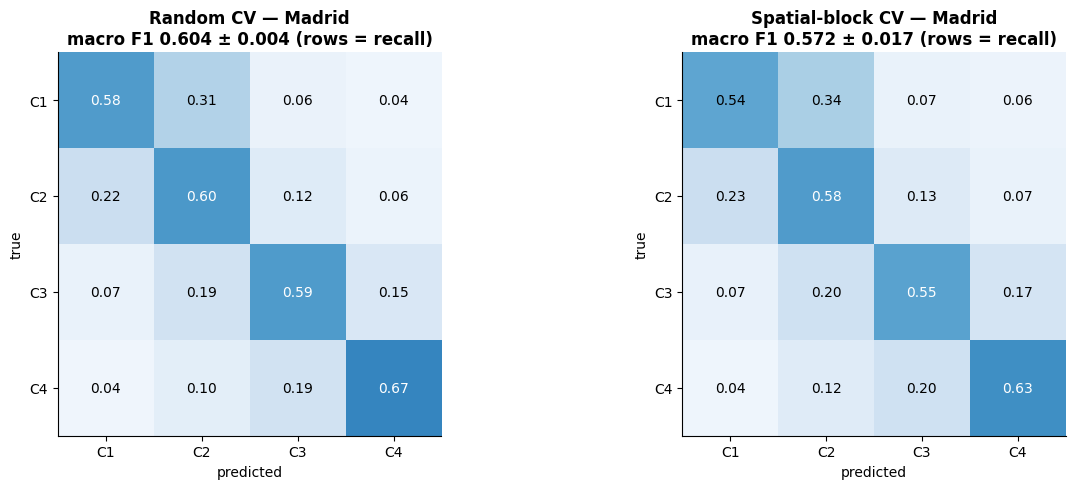

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, yt, yp, s) in zip(axes, [('Random CV', yt_r, yp_r, s_rand), ('Spatial-block CV', yt_s, yp_s, s_spat)]):
    cm = confusion_matrix(yt, yp, labels=[1, 2, 3, 4]); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1); ax.grid(False)
    for i in range(4):
        for j in range(4): ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', color='white' if cmn[i, j] > .55 else 'black')
    ax.set_xticks(range(4)); ax.set_xticklabels([f'C{k}' for k in [1, 2, 3, 4]]); ax.set_yticks(range(4)); ax.set_yticklabels([f'C{k}' for k in [1, 2, 3, 4]])
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(f'{title} — Madrid\nmacro F1 {s.mean():.3f} ± {s.std():.3f} (rows = recall)', fontweight='bold')
plt.tight_layout(); plt.show()

**What we learned:** random CV gives **0.604 ± 0.004**, spatial-block CV **0.572 ± 0.017** — the random split is **≈ 0.03 too optimistic** and its error bar is unrealistically small, because test pixels have near-identical neighbours in training. Notice also in both matrices that most mistakes are between **neighbouring classes** (1↔2, 2↔3, 3↔4). We report the competition's required CV, but we should **choose features and models using spatial-block CV**, because that is closer to how a model performs on genuinely new areas (and on the organisers' hidden test set).

### 13.4 Quick look at the city gap (preview)

Same quick model, trained on **all Madrid**, applied to **all Amsterdam** without any Amsterdam labels (*zero-shot*). We compare raw features vs features **standardised within each city** (each city's features shifted to mean 0, std 1 using that city's own *unlabelled* pixels — no labels needed).

In [37]:
from sklearn.preprocessing import StandardScaler
ams = Xf['Amsterdam'].join(pix['Amsterdam'].set_index(PID)[['age_class']], how='inner')
Xa, ya = ams[Xf['Amsterdam'].columns].values, ams.age_class.values

def zero_shot(Xtr, Xte):
    m = HistGradientBoostingClassifier(max_iter=200, class_weight='balanced', random_state=SEED).fit(Xtr, y)
    return f1_score(ya, m.predict(Xte), average='macro')

f_raw  = zero_shot(X, Xa)
f_city = zero_shot(StandardScaler().fit_transform(X), StandardScaler().fit_transform(Xa))
print(f"Zero-shot Madrid → Amsterdam, raw features            : macro F1 = {f_raw:.3f}")
print(f"Zero-shot Madrid → Amsterdam, per-city standardisation: macro F1 = {f_city:.3f}")

Zero-shot Madrid → Amsterdam, raw features            : macro F1 = 0.381
Zero-shot Madrid → Amsterdam, per-city standardisation: macro F1 = 0.439


**Result:** raw features → **0.381**; per-city standardisation → **0.439**. Simply putting each city on its own scale (using no labels at all) gains **≈ +0.06 macro F1**. This is strong evidence for the domain-shift advice in Part 12.

### 13.5 The required few-shot protocol (Step 4 of the challenge)

For each *n* ∈ {5, 25, 50, 100, 200}, repeated with several random seeds:
1. **Support set** = *n* random labelled Amsterdam pixels **per class** (4·n in total).
2. Adapt the Madrid model using only the support set (+ any unlabelled Amsterdam data).
3. **Query set** = all other Amsterdam pixels → compute macro F1.
4. Report mean ± std over the repeats; plot F1 vs log₂(n).

The helper below draws the support set reproducibly. Amsterdam's smallest class has enough pixels for n = 200.

In [38]:
def sample_support(y, n, seed):
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.where(y == k)[0], n, replace=False) for k in np.unique(y)])
    query = np.setdiff1d(np.arange(len(y)), idx)
    return idx, query

for n in [5, 25, 50, 100, 200]:
    s, q = sample_support(ya, n, SEED)
    print(f"n = {n:3d} per class → support {len(s):4d} labelled pixels, query {len(q):,} pixels "
          f"(log2 n = {np.log2(n):.2f})")
print("Smallest Amsterdam class size:", np.bincount(ya)[1:].min())

n =   5 per class → support   20 labelled pixels, query 25,972 pixels (log2 n = 2.32)
n =  25 per class → support  100 labelled pixels, query 25,892 pixels (log2 n = 4.64)
n =  50 per class → support  200 labelled pixels, query 25,792 pixels (log2 n = 5.64)
n = 100 per class → support  400 labelled pixels, query 25,592 pixels (log2 n = 6.64)
n = 200 per class → support  800 labelled pixels, query 25,192 pixels (log2 n = 7.64)
Smallest Amsterdam class size: 2877


---
# Part 14 — Save the clean data

We save, in the `clean/` folder:
- `{city}_yearly_clean.parquet` — **one clean value per pixel per year** (our composite) + `n_photos`, `season`, `month`.
- `{city}_pixels.parquet` — **one row per pixel**: location, `wmy`, `coverage`, `age_class`, `n_years`.
- `bad_scenes.csv` — the broken scenes we removed.

Notebook 3 (features) can start from these files instead of the raw data.

In [39]:
for c in CITIES:
    comp[c].assign(city=c).to_parquet(OUT_DIR / f'{c.lower()}_yearly_clean.parquet', index=False)
    pix[c].to_parquet(OUT_DIR / f'{c.lower()}_pixels.parquet', index=False)
pd.DataFrame([(c, s) for c in CITIES for s in sorted(BAD_SCENES[c])], columns=['city', 'scene_id']).to_csv(OUT_DIR / 'bad_scenes.csv', index=False)
for f in sorted(OUT_DIR.iterdir()):
    print(f"{f.name:35s} {f.stat().st_size/1e6:8.1f} MB")

amsterdam_pixels.parquet                 0.1 MB
amsterdam_yearly_clean.parquet          16.6 MB
bad_scenes.csv                           0.0 MB
madrid_pixels.parquet                    0.4 MB
madrid_yearly_clean.parquet             61.4 MB


---
# Part 15 — Summary & action list

### What our data is
- **Two cities**, one file each. **One row = one 30 m pixel in one year (1984–2025)**; each row holds **up to 3 satellite photos** of that year (`_1 _2 _3`).
- **Madrid**: 76 263 pixels × ~42 years = 3.17 M rows. **Amsterdam**: 25 992 pixels, 1.06 M rows.
- **48 columns**: 12 pixel columns + 3 × 12 photo columns. No missing values, no duplicates.

### What every column is for
| Use | Columns |
|---|---|
| **Input** | `Blue Green Red NIR SWIR1 SWIR2` × 3 photos |
| **Cleaning** | `qa_valid`, `QA_PIXEL`, `QA_RADSAT`, `scene_id` |
| **Control season / sensor** | `doy`, `dataset` |
| **Organise time & space** | `year`, `px_key`, `py_key` |
| **Answer** | `weighted_mean_year` → age class |
| **Trust / weight** | `coverage` |
| **Drop** | `pixel_x`, `pixel_y`, `row`, `col` (copies), `usable_label` (always True), `pixel_id`, `city` |

### The biggest findings
| # | Finding | Evidence | Consequence |
|---|---|---|---|
| 1 | Photos are **not summer-only** | only 50 % (Madrid) / 31 % (Amsterdam) of clean photos in Jun–Aug | season adds noise → prefer warm-season photos |
| 2 | Starter method wastes data | keeps 1 photo/year, discards ~60 % of clean photos | our **warm-season median** cuts year-to-year noise by **46 % (Madrid) / 40 % (Amsterdam)** |
| 3 | **3 broken scenes** pass `qa_valid` | Blue ≈ 36 800 – 64 000 for whole scenes | drop the scenes completely |
| 4 | Amsterdam is **cloudy** | 27 % of observations not valid vs 6 % in Madrid | fewer photos per year, noisier series |
| 5 | **Sensor offsets** remain | e.g. Amsterdam OLI years darker in NIR | use medians, ratios, per-city scaling |
| 6 | **Label heaping** | 2 227 Madrid pixels exactly at **1960** = the class 1/2 boundary (16 % of class 1) | test with / without them |
| 7 | Many **boundary pixels** | 5–9 % of pixels within ±2 years of a class edge | errors between neighbouring classes are expected |
| 8 | Labels are **mixtures** for old classes | whole-number years: class 4 mostly, class 1 much less | class 1/2 labels are noisier |
| 9 | **Imbalance** moderate, **prior shift** large | Madrid 2.0 : 1, Amsterdam 3.1 : 1; class 1 +11 pts, class 4 −11 pts in Amsterdam | class weights + re-calibrate to Amsterdam's mix |
| 10 | **Domain shift** | Amsterdam darker in every band, greener | per-city standardisation: zero-shot 0.381 → **0.439** |
| 11 | **Strong spatial autocorrelation** | neighbour has same class 76 % / 87 % of the time (chance ≈ 27 %) | great feature; but random CV over-estimates by ≈ 0.03 |

### Cleaning recipe (implemented above, saved in `clean/`)
1. Long format: one row per photo.
2. Drop: not `qa_valid` → broken scenes → saturated → zero bands → high cirrus → Blue > 15 000.
3. One value per pixel-year = **median of clean May–September photos** (fallback: all months).
4. Result: Madrid 3.15 M, Amsterdam 1.06 M clean pixel-years; no pixel lost.

### Action list for the team
| Priority | Action | Owner |
|---|---|---|
| 1 | Use `clean/*_yearly_clean.parquet` as the starting point for features | everyone |
| 2 | Build features that **transfer**: indices (NDVI, NDBI …), **change / construction-year features**, early-vs-late differences, values **standardised per city** | features |
| 3 | Add **neighbourhood features** (3×3 / 5×5 averages around each pixel) | features |
| 4 | Train with **class weights**; tune by **macro F1**; always inspect the confusion matrix | model |
| 5 | Evaluate with **spatial-block CV** for decisions; report the required CV too | evaluation |
| 6 | For Amsterdam: per-city scaling + **re-calibrate to Amsterdam's class mix** + use unlabelled pixels (self-training) | transfer |
| 7 | Experiment: drop / down-weight the 1960 heap and low-coverage pixels | model |
| 8 | Keep everything reproducible: fixed `SEED`, `n` as a parameter, `sample_support()` for few-shot draws | everyone |
| 9 | Ask organisers: external data allowed? 4 or 5 Amsterdam F1 scores? submission format? | team lead |